This project is a Statistical Inference / Web Scraping / Statistical Analysis project based on hockey team performance data. The data is scraped directly from `https://www.scrapethissite.com/pages/forms/`. It serves as a unified statistical inference lab project covering data extraction, cleaning, descriptive statistics, visualization, probability, sampling, hypothesis testing, correlation, regression, and ANOVA.

The objective of this project is to perform a comprehensive statistical analysis on hockey team performance using real web-scraped data. All tasks use a single, unified dataset collected directly from the web source.

**Aim:** To extract hockey team statistics from a web page using web scraping techniques.
**Objective:** To navigate pagination, extract tabular data, and store it in a structured DataFrame.
**Data Source:** https://www.scrapethissite.com/pages/forms/
**Why the source is suitable:** It contains real paginated tabular data, which is ideal for demonstrating scraping and statistical analysis.
**Libraries Used:** `requests`, `BeautifulSoup`, `pandas`
**Web Scraping Methodology:**
1. **HTTP Request:** We send a GET request using the `requests` library.
2. **HTML Parsing:** The response content is parsed using `BeautifulSoup`.
3. **Table Extraction:** We locate the `table` tag and iterate through the `tr` rows to extract data.
4. **Pagination Handling:** We identify the maximum number of pages from the pagination elements and loop through all pages.
5. **DataFrame Creation:** Finally, the collected records are converted into a `pandas` DataFrame.

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
import time

import warnings
warnings.filterwarnings('ignore')

base_url = "https://www.scrapethissite.com/pages/forms/"
data = []

print("Starting web scraping...")
response = requests.get(base_url, timeout=10)
soup = BeautifulSoup(response.content, 'html.parser')

pagination = soup.find('ul', class_='pagination')
if pagination:
    pages = pagination.find_all('li')
    max_page = 1
    for page in pages:
        text = page.text.strip()
        if text.isdigit():
            max_page = max(max_page, int(text))
else:
    max_page = 1

print(f"Total pages detected: {max_page}")

for page_num in range(1, max_page + 1):
    url = f"{base_url}?page_num={page_num}"
    res = requests.get(url, timeout=10)
    page_soup = BeautifulSoup(res.content, 'html.parser')
    table = page_soup.find('table', class_='table')
    if table:
        headers = [th.text.strip() for th in table.find('tr').find_all('th')]
        rows = table.find_all('tr', class_='team')
        for row in rows:
            cols = row.find_all('td')
            cols = [ele.text.strip() for ele in cols]
            data.append(cols)
    time.sleep(0.25)

df_raw = pd.DataFrame(data, columns=headers)
df_raw.to_csv('hockey_team_performance_raw.csv', index=False)

print(f"Number of pages scraped: {max_page}")
print(f"Number of records obtained: {len(df_raw)}")
print(f"Dataset columns: {list(df_raw.columns)}")
print(f"DataFrame shape: {df_raw.shape}")

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.0.post1)/charset_normalizer (3.4.6) doesn't match a supported version!
  warnings.warn(


Starting web scraping...


Total pages detected: 24


Number of pages scraped: 24
Number of records obtained: 582
Dataset columns: ['Team Name', 'Year', 'Wins', 'Losses', 'OT Losses', 'Win %', 'Goals For (GF)', 'Goals Against (GA)', '+ / -']
DataFrame shape: (582, 9)


In [2]:
print("First 10 records:")
display(df_raw.head(10))
print("\nLast 10 records:")
display(df_raw.tail(10))

First 10 records:


,Team Name,Year,Wins,Losses,OT Losses,Win %,Goals For (GF),Goals Against (GA),+ / -
0,Boston Bruins,1990,44,24,,0.55,299,264,35
1,Buffalo Sabres,1990,31,30,,0.388,292,278,14
2,Calgary Flames,1990,46,26,,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,,0.425,273,298,-25
5,Edmonton Oilers,1990,37,37,,0.463,272,272,0
6,Hartford Whalers,1990,31,38,,0.388,238,276,-38
7,Los Angeles Kings,1990,46,24,,0.575,340,254,86
8,Minnesota North Stars,1990,27,39,,0.338,256,266,-10
9,Montreal Canadiens,1990,39,30,,0.487,273,249,24



Last 10 records:


,Team Name,Year,Wins,Losses,OT Losses,Win %,Goals For (GF),Goals Against (GA),+ / -
572,Philadelphia Flyers,2011,47,26,9,0.573,264,232,32
573,Phoenix Coyotes,2011,42,27,13,0.512,216,204,12
574,Pittsburgh Penguins,2011,51,25,6,0.622,282,221,61
575,San Jose Sharks,2011,43,29,10,0.524,228,210,18
576,St. Louis Blues,2011,49,22,11,0.598,210,165,45
577,Tampa Bay Lightning,2011,38,36,8,0.463,235,281,-46
578,Toronto Maple Leafs,2011,35,37,10,0.427,231,264,-33
579,Vancouver Canucks,2011,51,22,9,0.622,249,198,51
580,Washington Capitals,2011,42,32,8,0.512,222,230,-8
581,Winnipeg Jets,2011,37,35,10,0.451,225,246,-21


**Conclusion:** The web scraping methodology successfully navigated through all the pages, extracting structured records into a single raw dataset.

**Aim:** To clean the raw data, perform feature engineering, and calculate descriptive statistics.

**Data Cleaning Methodology:**
- Handle missing values: OT Losses were not recorded for certain historical seasons in the source. These missing values were retained as NaN because this variable is not required for the subsequent statistical inference analyses.
- Standardize column names.
- Convert textual numerical data into proper numerical data types.
- Check for duplicates.

**Feature Engineering:**
- `Goal_Difference` = `Goals_For` - `Goals_Against`
- `Decade`: Grouping `Year` into decades.

In [3]:
df_clean = df_raw.copy()

print(f"Raw rows: {len(df_clean)}")
df_clean.columns = ['Team_Name', 'Year', 'Wins', 'Losses', 'OT_Losses', 'Win_Pct', 'Goals_For', 'Goals_Against', 'Goal_Diff']

numeric_cols = ['Year', 'Wins', 'Losses', 'OT_Losses', 'Win_Pct', 'Goals_For', 'Goals_Against', 'Goal_Diff']
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

print("\nMissing values before cleaning:")
print(df_clean.isnull().sum())

initial_len = len(df_clean)
df_clean.drop_duplicates(subset=['Team_Name', 'Year'], inplace=True)
print(f"\nRows removed due to duplication (Team_Name + Year): {initial_len - len(df_clean)}")

core_cols = ['Team_Name', 'Year', 'Wins', 'Losses', 'Win_Pct', 'Goals_For', 'Goals_Against', 'Goal_Diff']
initial_len = len(df_clean)
df_clean.dropna(subset=core_cols, inplace=True)
print(f"Rows removed due to missing core analytical variables: {initial_len - len(df_clean)}")

print("\nNote: OT Losses were not recorded for certain historical seasons in the source. These missing values were retained because this variable is not required for the subsequent statistical inference analyses.")

df_clean['Decade'] = (df_clean['Year'] // 10 * 10).astype(int).astype(str) + 's'
df_clean['Goal_Difference'] = df_clean['Goals_For'] - df_clean['Goals_Against']

df_clean.to_csv('hockey_team_performance_cleaned.csv', index=False)

print(f"\nCleaned rows: {len(df_clean)}")
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nValid Ranges Check:")
for col in ['Win_Pct', 'Wins', 'Losses', 'Goals_For', 'Goals_Against', 'Goal_Difference']:
    print(f"{col}: Min = {df_clean[col].min()}, Max = {df_clean[col].max()}")

display(df_clean.head())

Raw rows: 582

Missing values before cleaning:
Team_Name          0
Year               0
Wins               0
Losses             0
OT_Losses        224
Win_Pct            0
Goals_For          0
Goals_Against      0
Goal_Diff          0
dtype: int64

Rows removed due to duplication (Team_Name + Year): 0
Rows removed due to missing core analytical variables: 0

Note: OT Losses were not recorded for certain historical seasons in the source. These missing values were retained because this variable is not required for the subsequent statistical inference analyses.

Cleaned rows: 582

Missing values after cleaning:
Team_Name            0
Year                 0
Wins                 0
Losses               0
OT_Losses          224
Win_Pct              0
Goals_For            0
Goals_Against        0
Goal_Diff            0
Decade               0
Goal_Difference      0
dtype: int64

Valid Ranges Check:
Win_Pct: Min = 0.119, Max = 0.756
Wins: Min = 9, Max = 62
Losses: Min = 11, Max = 71
Goals_For: 

,Team_Name,Year,Wins,Losses,OT_Losses,Win_Pct,Goals_For,Goals_Against,Goal_Diff,Decade,Goal_Difference
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35,1990s,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14,1990s,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81,1990s,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73,1990s,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25,1990s,-25


In [4]:
cols_to_desc = ['Wins', 'Losses', 'Win_Pct', 'Goals_For', 'Goals_Against', 'Goal_Difference']
desc_stats = df_clean[cols_to_desc].describe().T

desc_stats['mode'] = df_clean[cols_to_desc].mode().iloc[0]
desc_stats['median'] = df_clean[cols_to_desc].median()
desc_stats['variance'] = df_clean[cols_to_desc].var()
desc_stats['range'] = desc_stats['max'] - desc_stats['min']
desc_stats['IQR'] = desc_stats['75%'] - desc_stats['25%']

desc_stats = desc_stats[['count', 'mean', 'median', 'mode', 'min', 'max', 'range', 'variance', 'std', '25%', '75%', 'IQR']]
desc_stats.columns = ['Count', 'Mean', 'Median', 'Mode', 'Minimum', 'Maximum', 'Range', 'Variance', 'Standard Deviation', 'Q1', 'Q3', 'IQR']

display(desc_stats)

,Count,Mean,Median,Mode,Minimum,Maximum,Range,Variance,Standard Deviation,Q1,Q3,IQR
Wins,582.0,36.943299,38.000,43.0,9.000,62.000,53.000,79.674921,8.926081,31.00,43.000,12.000
Losses,582.0,32.353952,31.000,27.0,11.000,71.000,60.000,70.752299,8.411439,27.00,37.000,10.000
Win_Pct,582.0,0.458519,0.463,0.5,0.119,0.756,0.637,0.010452,0.102237,0.39,0.534,0.144
Goals_For,582.0,234.063574,231.000,214.0,115.000,369.000,254.000,1644.214540,40.548915,211.00,254.000,43.000
Goals_Against,582.0,234.063574,232.500,209.0,115.000,414.000,299.000,1807.161184,42.510718,207.00,258.750,51.750
Goal_Difference,582.0,0.000000,4.000,35.0,-196.000,144.000,340.000,2050.048193,45.277458,-27.00,31.000,58.000


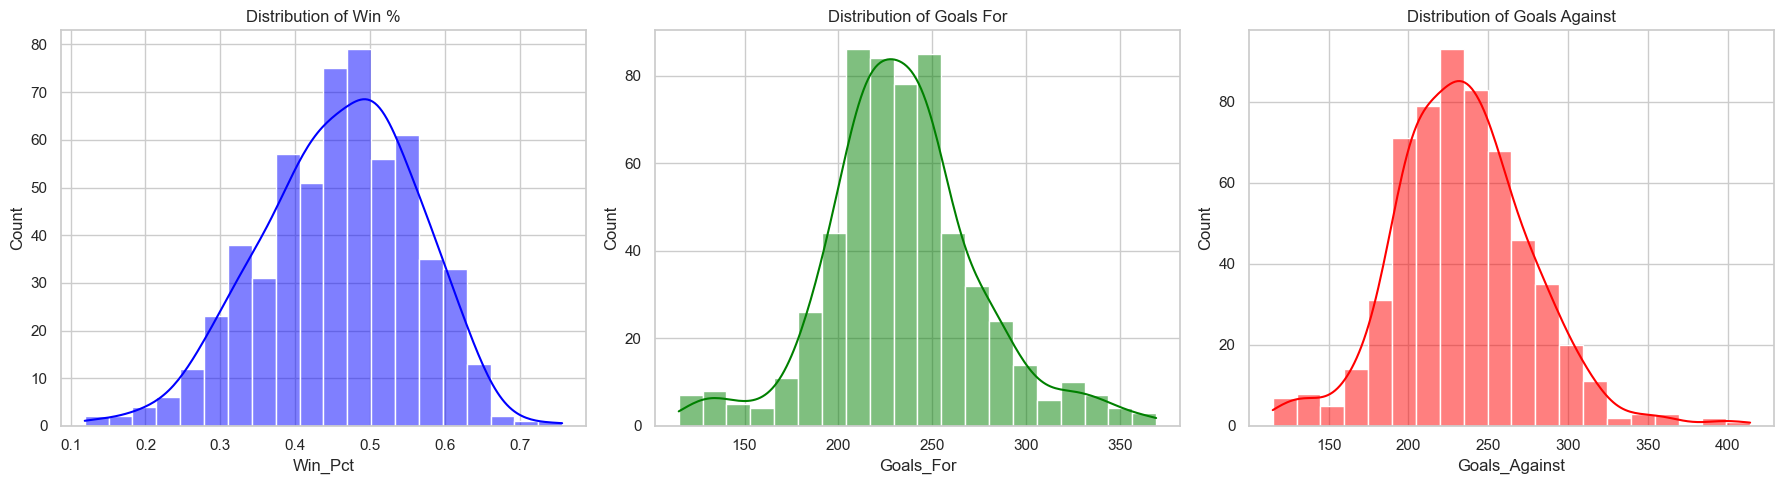

Data-Driven Interpretations:
- Win % distribution skewness is -0.31. The data is approximately symmetric.
- Goals For distribution skewness is 0.25. The data is approximately symmetric.
- Goals Against distribution skewness is 0.32. The data is approximately symmetric.


In [5]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_clean['Win_Pct'], kde=True, bins=20, color='blue', ax=axes[0])
axes[0].set_title('Distribution of Win %')

sns.histplot(df_clean['Goals_For'], kde=True, bins=20, color='green', ax=axes[1])
axes[1].set_title('Distribution of Goals For')

sns.histplot(df_clean['Goals_Against'], kde=True, bins=20, color='red', ax=axes[2])
axes[2].set_title('Distribution of Goals Against')

plt.tight_layout()
plt.show()

skew_win = df_clean['Win_Pct'].skew()
skew_gf = df_clean['Goals_For'].skew()
skew_ga = df_clean['Goals_Against'].skew()

print("Data-Driven Interpretations:")
print(f"- Win % distribution skewness is {skew_win:.2f}. The data {'shows skewness' if abs(skew_win) > 0.5 else 'is approximately symmetric'}.")
print(f"- Goals For distribution skewness is {skew_gf:.2f}. The data {'shows skewness' if abs(skew_gf) > 0.5 else 'is approximately symmetric'}.")
print(f"- Goals Against distribution skewness is {skew_ga:.2f}. The data {'shows skewness' if abs(skew_ga) > 0.5 else 'is approximately symmetric'}.")

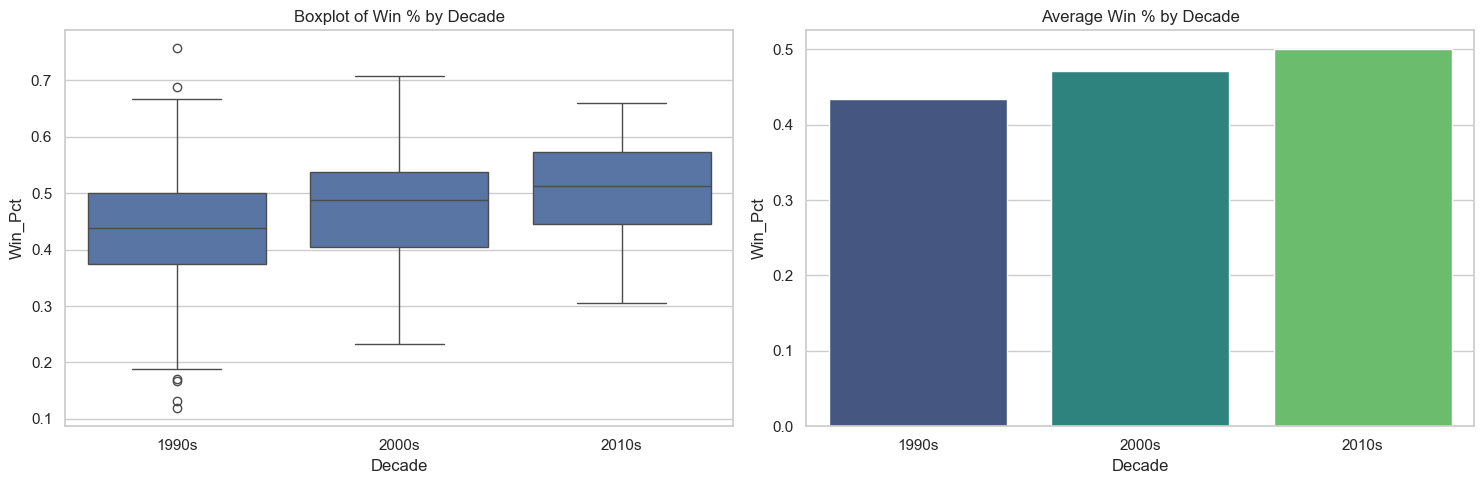

Interpretation:
The standard deviation of average Win % across decades is 0.0328. A low variance indicates a relatively consistent win distribution across different eras of the league.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x='Decade', y='Win_Pct', data=df_clean, order=sorted(df_clean['Decade'].unique()), ax=axes[0])
axes[0].set_title('Boxplot of Win % by Decade')

avg_win_pct = df_clean.groupby('Decade')['Win_Pct'].mean().reset_index()
sns.barplot(x='Decade', y='Win_Pct', data=avg_win_pct, palette='viridis', ax=axes[1])
axes[1].set_title('Average Win % by Decade')

plt.tight_layout()
plt.show()

pct_std = avg_win_pct['Win_Pct'].std()
print("Interpretation:")
print(f"The standard deviation of average Win % across decades is {pct_std:.4f}. A low variance indicates a relatively consistent win distribution across different eras of the league.")

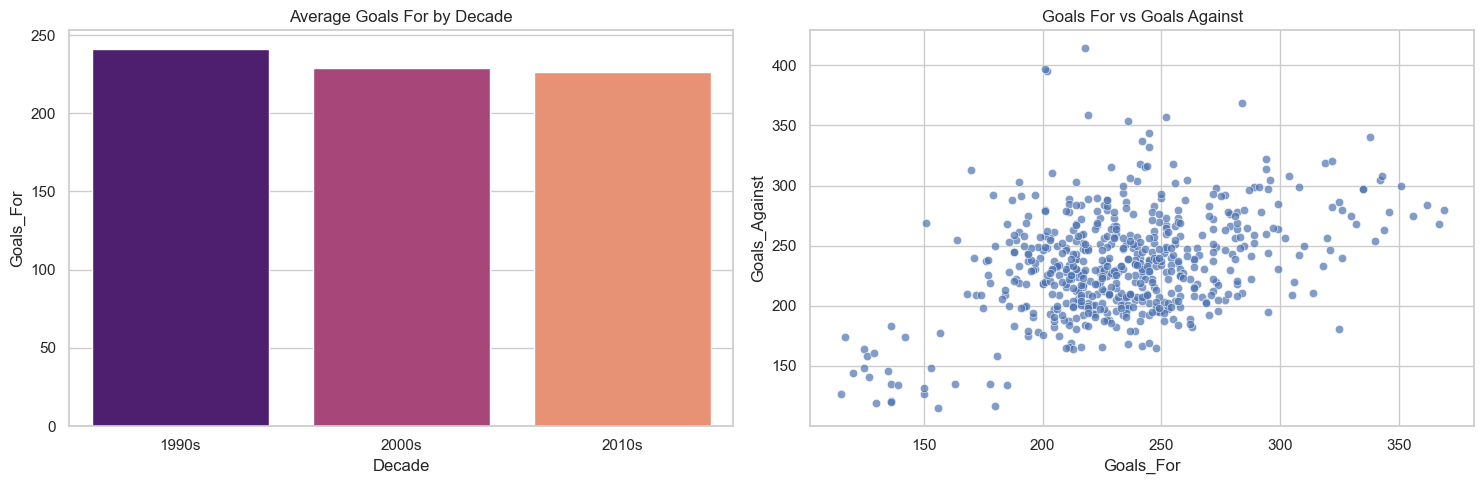

Interpretation:
Average Goals For peaked in the 1990s (241.0) and reached its minimum in the 2010s (226.6).
The linear relationship between Goals For and Goals Against shows a Pearson correlation of r = 0.406.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

avg_goals_for = df_clean.groupby('Decade')['Goals_For'].mean().reset_index()
sns.barplot(x='Decade', y='Goals_For', data=avg_goals_for, palette='magma', ax=axes[0])
axes[0].set_title('Average Goals For by Decade')

sns.scatterplot(x='Goals_For', y='Goals_Against', data=df_clean, alpha=0.7, ax=axes[1])
axes[1].set_title('Goals For vs Goals Against')

plt.tight_layout()
plt.show()

max_decade = avg_goals_for.loc[avg_goals_for['Goals_For'].idxmax()]
min_decade = avg_goals_for.loc[avg_goals_for['Goals_For'].idxmin()]
r_gfa, p_gfa = stats.pearsonr(df_clean['Goals_For'], df_clean['Goals_Against'])

print("Interpretation:")
print(f"Average Goals For peaked in the {max_decade['Decade']} ({max_decade['Goals_For']:.1f}) and reached its minimum in the {min_decade['Decade']} ({min_decade['Goals_For']:.1f}).")
print(f"The linear relationship between Goals For and Goals Against shows a Pearson correlation of r = {r_gfa:.3f}.")

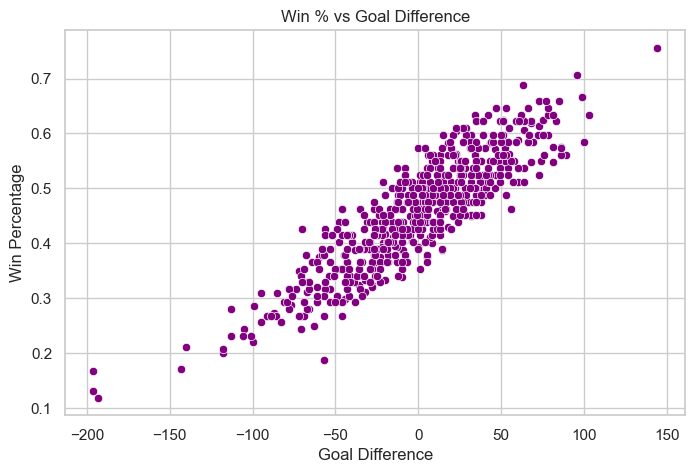

Interpretation:
The correlation between Goal Difference and Win % is r = 0.887. This mathematical magnitude strongly supports the observed scatterplot trajectory.


In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Goal_Difference', y='Win_Pct', data=df_clean, color='purple')
plt.title('Win % vs Goal Difference')
plt.xlabel('Goal Difference')
plt.ylabel('Win Percentage')
plt.show()

r_gd_win, p_gd_win = stats.pearsonr(df_clean['Goal_Difference'], df_clean['Win_Pct'])
print("Interpretation:")
print(f"The correlation between Goal Difference and Win % is r = {r_gd_win:.3f}. This mathematical magnitude strongly supports the observed scatterplot trajectory.")

**Aim:** To calculate exact probabilities from the real dataset and demonstrate basic sampling techniques.

In [9]:
total_observations = len(df_clean)

fav_win_500 = len(df_clean[df_clean['Win_Pct'] > 0.500])
prob_win_500 = fav_win_500 / total_observations

fav_win_600 = len(df_clean[df_clean['Win_Pct'] > 0.600])
prob_win_600 = fav_win_600 / total_observations

fav_gd_0 = len(df_clean[df_clean['Goal_Difference'] > 0])
prob_gd_0 = fav_gd_0 / total_observations

fav_wins_40 = len(df_clean[df_clean['Wins'] > 40])
prob_wins_40 = fav_wins_40 / total_observations

print(f"Total population size: {total_observations}")
print(f"P(Win % > 0.500): {fav_win_500} / {total_observations} = {prob_win_500:.4f}")
print(f"P(Win % > 0.600): {fav_win_600} / {total_observations} = {prob_win_600:.4f}")
print(f"P(Goal Difference > 0): {fav_gd_0} / {total_observations} = {prob_gd_0:.4f}")
print(f"P(Wins > 40): {fav_wins_40} / {total_observations} = {prob_wins_40:.4f}")

Total population size: 582
P(Win % > 0.500): 202 / 582 = 0.3471
P(Win % > 0.600): 38 / 582 = 0.0653
P(Goal Difference > 0): 311 / 582 = 0.5344
P(Wins > 40): 226 / 582 = 0.3883


In [10]:
sample_size = 30

srs_sample = df_clean.sample(n=sample_size, random_state=42)
print("1. Simple Random Sampling (SRS)")
print(f"Sample Size: {len(srs_sample)}")

k = len(df_clean) // sample_size
systematic_sample = df_clean.iloc[::k].head(sample_size)
print("\n2. Systematic Sampling")
print(f"Sample Size: {len(systematic_sample)}")

print("\n3. Stratified Sampling")
proportions = df_clean['Decade'].value_counts(normalize=True)
stratum_sizes = (proportions * sample_size).round().astype(int)

diff = sample_size - stratum_sizes.sum()
if diff != 0:
    largest = stratum_sizes.idxmax()
    stratum_sizes[largest] += diff

stratified_sample = pd.DataFrame()
for decade, size in stratum_sizes.items():
    if size > 0:
        stratum = df_clean[df_clean['Decade'] == decade]
        sampled = stratum.sample(n=size, random_state=42)
        stratified_sample = pd.concat([stratified_sample, sampled])

print(f"Population Size: {total_observations}")
print(f"Target Sample Size: {sample_size}")
print(f"Actual Sample Size Obtained: {len(stratified_sample)}")
print("\nSample Size per Stratum:")
print(stratum_sizes)
print("\nSelected Records (First 5):")
display(stratified_sample[['Team_Name', 'Year', 'Decade', 'Win_Pct']].head())

1. Simple Random Sampling (SRS)
Sample Size: 30

2. Systematic Sampling
Sample Size: 30

3. Stratified Sampling
Population Size: 582
Target Sample Size: 30
Actual Sample Size Obtained: 30

Sample Size per Stratum:
Decade
2000s    14
1990s    13
2010s     3
Name: proportion, dtype: int64

Selected Records (First 5):


,Team_Name,Year,Decade,Win_Pct
282,Mighty Ducks of Anaheim,2001,2000s,0.354
368,Tampa Bay Lightning,2003,2000s,0.561
331,New York Rangers,2002,2000s,0.390
379,Chicago Blackhawks,2005,2000s,0.317
448,Nashville Predators,2007,2000s,0.500


**Aim:** To demonstrate the Central Limit Theorem (CLT) using sampling distributions.  
**Variable:** Win %  
**Method:** We will repeatedly draw random samples (n=30) from the actual scraped population and calculate the sample mean.

Population Mean (μ): 0.45852
Mean of Sample Means: 0.45848
Population Standard Deviation (σ): 0.10215
Theoretical Standard Error (σ/√n): 0.01865
Observed SD of Sample Means: 0.01853


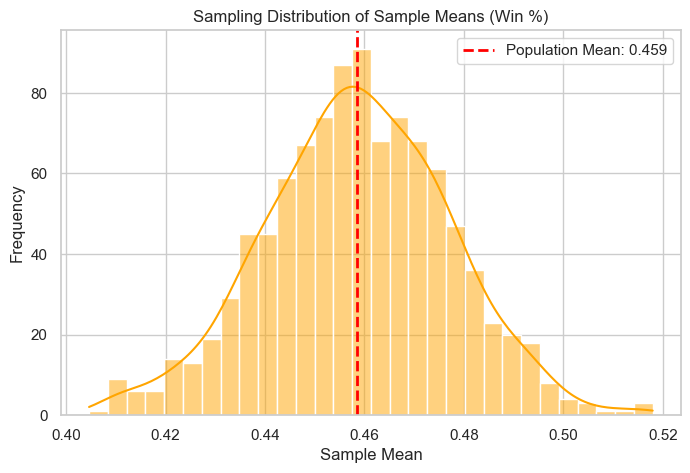

Central Limit Theorem Interpretation:
As the number of samples increases, the distribution of the sample means approximately approaches a normal distribution. The mean of sample means closely approximates the true population mean.


In [11]:
pop_mean = df_clean['Win_Pct'].mean()
pop_std = df_clean['Win_Pct'].std(ddof=0) # Population standard deviation

n = 30
num_samples = 1000
sample_means = []

np.random.seed(42)
for _ in range(num_samples):
    sample = df_clean['Win_Pct'].sample(n=n, replace=True)
    sample_means.append(sample.mean())

mean_of_sample_means = np.mean(sample_means)
std_of_sample_means = np.std(sample_means, ddof=1)
theoretical_se = pop_std / np.sqrt(n)

print(f"Population Mean (μ): {pop_mean:.5f}")
print(f"Mean of Sample Means: {mean_of_sample_means:.5f}")
print(f"Population Standard Deviation (σ): {pop_std:.5f}")
print(f"Theoretical Standard Error (σ/√n): {theoretical_se:.5f}")
print(f"Observed SD of Sample Means: {std_of_sample_means:.5f}")

plt.figure(figsize=(8, 5))
sns.histplot(sample_means, kde=True, bins=30, color='orange')
plt.axvline(pop_mean, color='red', linestyle='dashed', linewidth=2, label=f'Population Mean: {pop_mean:.3f}')
plt.title('Sampling Distribution of Sample Means (Win %)')
plt.xlabel('Sample Mean')
plt.ylabel('Frequency')
plt.legend()
plt.show()

print("Central Limit Theorem Interpretation:")
print("As the number of samples increases, the distribution of the sample means approximately approaches a normal distribution. The mean of sample means closely approximates the true population mean.")

**Research Question:** Is the average team Win % significantly different from 0.500?

**Hypotheses:**
- **H0:** μ = 0.500
- **H1:** μ ≠ 0.500

**Significance Level (α):** 0.05
**Test Selected:** One-sample t-test

In [12]:
alpha = 0.05
test_value = 0.500

stat, p_shapiro = stats.shapiro(df_clean['Win_Pct'])
print(f"Assumptions Check: Shapiro-Wilk test for Normality -> p-value = {p_shapiro:.4e}")
if p_shapiro < alpha:
    print("Note: The normality test rejected the normality assumption at alpha = 0.05, but due to the large sample size (N=582), the t-test remains robust per the CLT.\n")
else:
    print("Note: The normality test did not reject the normality assumption at alpha = 0.05.\n")

t_stat, p_value = stats.ttest_1samp(df_clean['Win_Pct'], popmean=test_value)

print(f"Test Statistic (t): {t_stat:.4f}")
print(f"P-value: {p_value:.4e}")
print(f"Alpha: {alpha}")

if p_value < alpha:
    print("\nDecision: Reject the null hypothesis (H0).")
    print("Conclusion: The average Win % is significantly different from 0.500.")
else:
    print("\nDecision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: There is no significant evidence that the average Win % is different from 0.500.")

Assumptions Check: Shapiro-Wilk test for Normality -> p-value = 1.9100e-03
Note: The normality test rejected the normality assumption at alpha = 0.05, but due to the large sample size (N=582), the t-test remains robust per the CLT.

Test Statistic (t): -9.7882
P-value: 4.8128e-21
Alpha: 0.05

Decision: Reject the null hypothesis (H0).
Conclusion: The average Win % is significantly different from 0.500.


**Aim:** To estimate the unknown population mean team win percentage ($\mu$) with 95% confidence using sample data.

**Statistical Formulation:**
- **Parameter of Interest:** Population mean team win percentage ($\mu$).
- **Sample Estimator:** Sample mean ($\bar{x}$).
- **Why a t-based Interval?** The true population standard deviation ($\sigma$) is unknown and must be estimated using the sample standard deviation ($s$). Therefore, the sampling distribution of the studentized mean follows a Student's $t$-distribution with $df = n - 1$ degrees of freedom.
- **Formula:** 
  $$\\text{CI}_{95\\%} = \\bar{x} \\pm t_{\\alpha/2, n-1} \\cdot \\text{SE} = \\bar{x} \\pm t_{0.025, n-1} \\cdot \\left(\\frac{s}{\\sqrt{n}}\\right)$$
- **Data Handling:** Computed strictly on valid, non-missing observations from `df_clean['Win_Pct']`.

**Interpretation Principle & Critical Distinction:**
- A 95% confidence interval means that in repeated sampling, 95% of such constructed intervals would contain the true population mean $\mu$.
- **Crucial Common Misconception Avoided:** This interval **does NOT** contain 95% of individual teams' win percentages. Individual team win percentages exhibit substantial dispersion ($s \\approx 0.102$), whereas this confidence interval measures the precision of the *mean* estimate ($\text{SE} = s/\\sqrt{n} \\approx 0.0042$).

Sample Size (n):                 582
Sample Mean (x̄):                 0.45852
Sample Standard Deviation (s):   0.10224
Standard Error (SE = s/√n):      0.00424
Degrees of Freedom (df = n - 1): 581
Confidence Level:                95.0%
Critical Value (t*):             1.96406
Margin of Error (ME):            0.00832
95% Confidence Interval:         [0.45020, 0.46684]


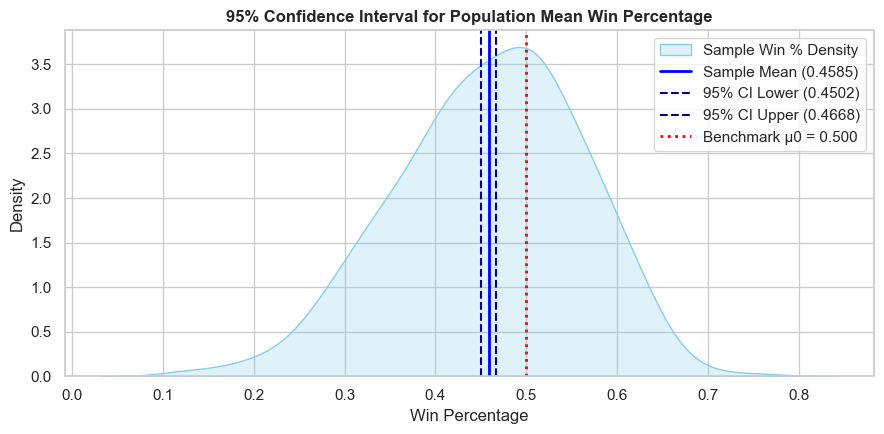


Interpretation in Hockey Performance Context:
We are 95% confident that the true population mean win percentage across all NHL team-seasons
lies within the interval [0.4502, 0.4668].

Critical Statistical Distinction:
• This confidence interval reflects sampling uncertainty regarding the POPULATION MEAN (μ).
• It does NOT state that 95% of individual teams have a win percentage in this range.
  Individual team records vary widely (s = 0.1022, range = [0.119, 0.756]),
  while the mean is estimated with high precision due to the sample size (N = 582).
• Because the entire 95% confidence interval lies strictly below 0.500, the data confirms
  that historical NHL team-season winning percentages average significantly below .500.
  This occurs because overtime losses and historical ties were recorded as non-wins in win percentage calculation.


In [13]:
win_pct_series = df_clean['Win_Pct'].dropna()
n_obs = len(win_pct_series)
sample_mean = win_pct_series.mean()
sample_std = win_pct_series.std(ddof=1)
standard_error = sample_std / np.sqrt(n_obs)
confidence_level = 0.95
alpha_ci = 1 - confidence_level
df_t = n_obs - 1

# Critical t-value for 95% confidence
t_critical = stats.t.ppf(1 - alpha_ci / 2, df=df_t)
margin_of_error = t_critical * standard_error

ci_lower = sample_mean - margin_of_error
ci_upper = sample_mean + margin_of_error

print(f"Sample Size (n):                 {n_obs}")
print(f"Sample Mean (x̄):                 {sample_mean:.5f}")
print(f"Sample Standard Deviation (s):   {sample_std:.5f}")
print(f"Standard Error (SE = s/√n):      {standard_error:.5f}")
print(f"Degrees of Freedom (df = n - 1): {df_t}")
print(f"Confidence Level:                {confidence_level * 100:.1f}%")
print(f"Critical Value (t*):             {t_critical:.5f}")
print(f"Margin of Error (ME):            {margin_of_error:.5f}")
print(f"95% Confidence Interval:         [{ci_lower:.5f}, {ci_upper:.5f}]")

plt.figure(figsize=(9, 4.5))
sns.kdeplot(win_pct_series, fill=True, color='skyblue', label='Sample Win % Density')
plt.axvline(sample_mean, color='blue', linestyle='-', linewidth=2, label=f'Sample Mean ({sample_mean:.4f})')
plt.axvline(ci_lower, color='darkblue', linestyle='--', linewidth=1.5, label=f'95% CI Lower ({ci_lower:.4f})')
plt.axvline(ci_upper, color='darkblue', linestyle='--', linewidth=1.5, label=f'95% CI Upper ({ci_upper:.4f})')
plt.axvline(0.500, color='red', linestyle=':', linewidth=2, label='Benchmark μ0 = 0.500')
plt.title('95% Confidence Interval for Population Mean Win Percentage', fontsize=12, fontweight='bold')
plt.xlabel('Win Percentage')
plt.ylabel('Density')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

print("\nInterpretation in Hockey Performance Context:")
print(f"We are 95% confident that the true population mean win percentage across all NHL team-seasons")
print(f"lies within the interval [{ci_lower:.4f}, {ci_upper:.4f}].")
print("\nCritical Statistical Distinction:")
print("• This confidence interval reflects sampling uncertainty regarding the POPULATION MEAN (μ).")
print("• It does NOT state that 95% of individual teams have a win percentage in this range.")
print(f"  Individual team records vary widely (s = {sample_std:.4f}, range = [{win_pct_series.min():.3f}, {win_pct_series.max():.3f}]),")
print(f"  while the mean is estimated with high precision due to the sample size (N = {n_obs}).")
print("• Because the entire 95% confidence interval lies strictly below 0.500, the data confirms")
print("  that historical NHL team-season winning percentages average significantly below .500.")
print("  This occurs because overtime losses and historical ties were recorded as non-wins in win percentage calculation.")

**Aim:** To test whether the population mean team win percentage differs from 0.500 using a classical Z-test framework.

**Hypotheses & Setup:**
- **Research Question:** Does the population mean team Win % differ from 0.500?
- **Null Hypothesis ($H_0$):** $\mu = 0.500$ (The population mean win percentage is 0.500)
- **Alternative Hypothesis ($H_1$):** $\mu \neq 0.500$ (Two-sided: The population mean win percentage differs from 0.500)
- **Significance Level ($\alpha$):** 0.05
- **Classical Test Statistic:**
  $$Z = \frac{\bar{x} - \mu_0}{\sigma / \sqrt{n}}$$

**Methodological Constraint & Explicit Illustrative Label:**
- A classical one-sample Z-test strictly requires that the **population standard deviation ($\sigma$) is known a priori**.
- In practical sports analytics and for this hockey dataset, the true population standard deviation $\sigma$ is **unknown**.
- **Explicit Illustrative Label:** For pedagogical demonstration, this Z-test is purely illustrative, substituting the sample standard deviation ($s = 0.10224$) as an assumed $\sigma$.
- **No Independent Confirmation:** Substituting the sample standard deviation $s$ makes the Z-test mathematically and numerically almost identical to the studentized one-sample $t$-test ($Z = -9.7882$ vs. $t = -9.7882$). Therefore, the illustrative Z-test **does not provide independent confirmation** of the hypothesis test result.
- **P-Value Precision & Underflow Handling:** The two-sided p-value is calculated using the survival function $2 \cdot \text{sf}(|Z|)$ rather than $1 - \text{cdf}(|Z|)$ to prevent floating-point underflow, and extreme p-values are bounded rather than reported as an impossible exact zero probability.

In [14]:
# Classical Z-test requires known sigma; substituting sample standard deviation is purely illustrative
# Because s is substituted for sigma, the Z-test is numerically similar to the t-test and does not offer independent confirmation.
illustrative_sigma = sample_std
hypothesized_mean = 0.500

z_stat = (sample_mean - hypothesized_mean) / (illustrative_sigma / np.sqrt(n_obs))
# Two-sided p-value computed via survival function to prevent floating-point underflow
p_value_z = 2 * stats.norm.sf(abs(z_stat))
p_val_display = f"{p_value_z:.4e}" if p_value_z > 0 else "< 1.0000e-300"
alpha = 0.05

print(f"Research Question:       Does population mean Win % differ from 0.500?")
print(f"Null Hypothesis (H0):    μ = {hypothesized_mean:.3f}")
print(f"Alternative Hyp. (H1):   μ ≠ {hypothesized_mean:.3f}")
print(f"Significance Level (α):  {alpha}")
print(f"Sample Size (n):         {n_obs}")
print(f"Sample Mean (x̄):         {sample_mean:.5f}")
print(f"Illustrative Sigma (σ):  {illustrative_sigma:.5f} (Purely illustrative assumption; true sigma unknown)")
print(f"Standard Error (σ/√n):   {illustrative_sigma / np.sqrt(n_obs):.5f}")
print(f"Z-Statistic:             {z_stat:.5f}")
print(f"P-value (Two-sided):     {p_val_display}")

if p_value_z < alpha:
    print("Statistical Decision:    Reject the null hypothesis (H0).")
    print(f"Contextual Conclusion:   There is statistically overwhelming evidence (p = {p_val_display})")
    print("                         that the average Win % differs from 0.500.")
else:
    print("Statistical Decision:    Fail to reject the null hypothesis (H0).")
    print("Contextual Conclusion:   There is no significant evidence that mean Win % differs from 0.500.")

comparison_df = pd.DataFrame({
    'Property / Dimension': [
        'Population Sigma (σ) Requirement',
        'Standard Error Formulation',
        'Reference Null Distribution',
        'Test Statistic',
        'Calculated P-value',
        'Methodological Status for this Dataset'
    ],
    'Classical Z-Test (Illustrative)': [
        'Must be known a priori (assumed here as s)',
        f'σ_assumed / √n = {illustrative_sigma / np.sqrt(n_obs):.5f}',
        'Standard Normal N(0, 1)',
        f'Z = {z_stat:.4f}',
        f'{p_val_display}',
        'Illustrative only (not independent confirmation)'
    ],
    'One-Sample t-Test (Preserved)': [
        'Unknown (estimated by sample s)',
        f's / √n = {standard_error:.5f}',
        f'Student t (df = {df_t})',
        f't = {t_stat:.4f}',
        f'{p_value:.4e}',
        'Theoretically justified and robust'
    ]
})
display(comparison_df)

print("\nMethodological Summary:")
print("1. Why t-test is required: When population standard deviation is unknown, the t-test properly")
print("   accounts for the additional sampling error in estimating sigma with s.")
print("2. No Independent Confirmation: Substituting sample s for sigma in the Z-test produces virtually")
print("   the same numerical statistic as the t-test; it does NOT provide independent confirmation.")
print("3. Numerical Precision: Using the survival function (2 * sf) accurately avoids floating-point underflow.")

Research Question:       Does population mean Win % differ from 0.500?
Null Hypothesis (H0):    μ = 0.500
Alternative Hyp. (H1):   μ ≠ 0.500
Significance Level (α):  0.05
Sample Size (n):         582
Sample Mean (x̄):         0.45852
Illustrative Sigma (σ):  0.10224 (Purely illustrative assumption; true sigma unknown)
Standard Error (σ/√n):   0.00424
Z-Statistic:             -9.78825
P-value (Two-sided):     1.2647e-22
Statistical Decision:    Reject the null hypothesis (H0).
Contextual Conclusion:   There is statistically overwhelming evidence (p = 1.2647e-22)
                         that the average Win % differs from 0.500.


,Property / Dimension,Classical Z-Test (Illustrative),One-Sample t-Test (Preserved)
0,Population Sigma (σ) Requirement,Must be known a priori (assumed here as s),Unknown (estimated by sample s)
1,Standard Error Formulation,σ_assumed / √n = 0.00424,s / √n = 0.00424
2,Reference Null Distribution,"Standard Normal N(0, 1)",Student t (df = 581)
3,Test Statistic,Z = -9.7882,t = -9.7882
4,Calculated P-value,1.2647e-22,4.8128e-21
5,Methodological Status for this Dataset,Illustrative only (not independent confirmation),Theoretically justified and robust



Methodological Summary:
1. Why t-test is required: When population standard deviation is unknown, the t-test properly
   accounts for the additional sampling error in estimating sigma with s.
2. No Independent Confirmation: Substituting sample s for sigma in the Z-test produces virtually
   the same numerical statistic as the t-test; it does NOT provide independent confirmation.
3. Numerical Precision: Using the survival function (2 * sf) accurately avoids floating-point underflow.


**Aim:** To investigate relationships between different statistical metrics.

Goals For vs Win % -> r: 0.4801, p-value: 6.9844e-35
Goal Difference vs Win % -> r: 0.8872, p-value: 5.5867e-197
Goals For vs Goals Against -> r: 0.4065, p-value: 1.4559e-24


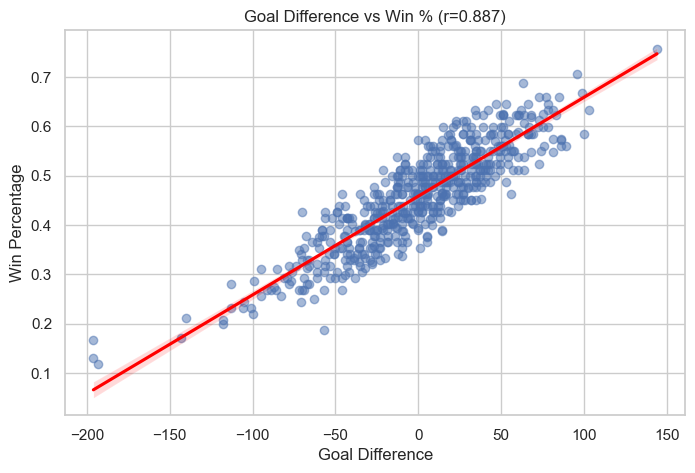

Interpretation:
Correlation values verify statistical relationships but do not imply causation. Goal Difference has a very high correlation mathematically linked to how sports games are determined.


In [15]:
r1, p1 = stats.pearsonr(df_clean['Goals_For'], df_clean['Win_Pct'])
print(f"Goals For vs Win % -> r: {r1:.4f}, p-value: {p1:.4e}")

r2, p2 = stats.pearsonr(df_clean['Goal_Difference'], df_clean['Win_Pct'])
print(f"Goal Difference vs Win % -> r: {r2:.4f}, p-value: {p2:.4e}")

r3, p3 = stats.pearsonr(df_clean['Goals_For'], df_clean['Goals_Against'])
print(f"Goals For vs Goals Against -> r: {r3:.4f}, p-value: {p3:.4e}")

plt.figure(figsize=(8, 5))
sns.regplot(x='Goal_Difference', y='Win_Pct', data=df_clean, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'Goal Difference vs Win % (r={r2:.3f})')
plt.xlabel('Goal Difference')
plt.ylabel('Win Percentage')
plt.show()

print("Interpretation:")
print("Correlation values verify statistical relationships but do not imply causation. Goal Difference has a very high correlation mathematically linked to how sports games are determined.")

**Aim:** To compute and examine the sample covariance matrix for core numerical performance variables.

**Theoretical Principles:**
- **Covariance Definition:** Sample covariance measures the degree to which two random variables change together:
  $$\\text{Cov}(X, Y) = \\frac{1}{n - 1} \\sum_{i=1}^n (X_i - \\bar{X})(Y_i - \\bar{Y})$$
- **Direction:** 
  - $\\text{Cov}(X, Y) > 0$: Variables tend to deviate from their means in the same direction.
  - $\\text{Cov}(X, Y) < 0$: Variables tend to deviate in opposite directions.
- **Scale and Unit Dependency:**
  - Unlike correlation, covariance is **unstandardized**. Its magnitude is expressed in the product of the measurement units of $X$ and $Y$ (e.g., $\\text{goals}^2$ vs $\\text{goals} \\times \\text{percentage}$).
  - **Critical Rule:** Covariance magnitude cannot be interpreted as a standardized measure of relationship strength; a larger covariance does not necessarily imply a stronger relationship.

In [16]:
cov_variables = ['Goals_For', 'Goals_Against', 'Goal_Difference', 'Win_Pct']

missing_counts = df_clean[cov_variables].isnull().sum()
print("Missing Values Check for Covariance Variables:")
print(missing_counts)
print(f"All {len(df_clean)} records have valid, complete observations across these variables.\n")

cov_matrix = df_clean[cov_variables].cov()
display(cov_matrix.round(4))

print("\nDirectional Relationships Identified:")
print(f"• Goals_For & Win_Pct:         Cov = +{cov_matrix.loc['Goals_For', 'Win_Pct']:.4f} (Positive: higher scoring co-occurs with higher win %)")
print(f"• Goals_Against & Win_Pct:     Cov = {cov_matrix.loc['Goals_Against', 'Win_Pct']:.4f} (Negative: higher goals conceded co-occurs with lower win %)")
print(f"• Goal_Difference & Win_Pct:   Cov = +{cov_matrix.loc['Goal_Difference', 'Win_Pct']:.4f} (Positive: net positive differential co-occurs with higher win %)")
print(f"• Goals_For & Goals_Against:   Cov = +{cov_matrix.loc['Goals_For', 'Goals_Against']:.4f} (Positive: higher-scoring eras elevated both scoring and conceding)")

print("\nScale and Unit Dependency Explanation:")
print(f"• Var(Goals_For) = {cov_matrix.loc['Goals_For', 'Goals_For']:.2f} goals² (measured on the scale of raw season goal totals).")
print(f"• Var(Win_Pct) = {cov_matrix.loc['Win_Pct', 'Win_Pct']:.4f} (measured as a bounded ratio between 0.0 and 1.0).")
print(f"• Cov(Goal_Difference, Win_Pct) = {cov_matrix.loc['Goal_Difference', 'Win_Pct']:.4f} goals × win %.")
print("• CRITICAL TAKEAWAY: The magnitude of covariance is heavily influenced by the measurement scale.")
print("  It cannot be directly compared across variable pairs without standardization into correlation.")

Missing Values Check for Covariance Variables:
Goals_For          0
Goals_Against      0
Goal_Difference    0
Win_Pct            0
dtype: int64
All 582 records have valid, complete observations across these variables.



,Goals_For,Goals_Against,Goal_Difference,Win_Pct
Goals_For,1644.2145,700.6638,943.5508,1.9901
Goals_Against,700.6638,1807.1612,-1106.4974,-2.1167
Goal_Difference,943.5508,-1106.4974,2050.0482,4.1068
Win_Pct,1.9901,-2.1167,4.1068,0.0105



Directional Relationships Identified:
• Goals_For & Win_Pct:         Cov = +1.9901 (Positive: higher scoring co-occurs with higher win %)
• Goals_Against & Win_Pct:     Cov = -2.1167 (Negative: higher goals conceded co-occurs with lower win %)
• Goal_Difference & Win_Pct:   Cov = +4.1068 (Positive: net positive differential co-occurs with higher win %)
• Goals_For & Goals_Against:   Cov = +700.6638 (Positive: higher-scoring eras elevated both scoring and conceding)

Scale and Unit Dependency Explanation:
• Var(Goals_For) = 1644.21 goals² (measured on the scale of raw season goal totals).
• Var(Win_Pct) = 0.0105 (measured as a bounded ratio between 0.0 and 1.0).
• Cov(Goal_Difference, Win_Pct) = 4.1068 goals × win %.
• CRITICAL TAKEAWAY: The magnitude of covariance is heavily influenced by the measurement scale.
  It cannot be directly compared across variable pairs without standardization into correlation.


**Aim:** To calculate Spearman's rank correlation coefficient ($\rho_s$) and test for statistically significant monotonic relationships.

**Methodology & Hypotheses:**
- **Spearman's $\rho_s$:** Computes Pearson correlation on the ranks of the data, measuring monotonic (consistently increasing or decreasing) relationships without requiring bivariate normality or linear functional form.
- **Hypotheses for Each Pair:**
  - **$H_0$:** $\rho_s = 0$ (No monotonic relationship in the population)
  - **$H_1$:** $\rho_s \neq 0$ (A significant monotonic relationship exists)
- **Significance Level:** $\alpha = 0.05$
- **Pairs Tested:**
  1. `Goals_For` vs `Win_Pct`
  2. `Goal_Difference` vs `Win_Pct`
  3. `Goals_Against` vs `Win_Pct`

In [17]:
spearman_pairs = [
    ('Goals_For', 'Win_Pct'),
    ('Goal_Difference', 'Win_Pct'),
    ('Goals_Against', 'Win_Pct')
]

alpha_spearman = 0.05
spearman_records = []

for var1, var2 in spearman_pairs:
    data_pair = df_clean[[var1, var2]].dropna()
    n_pair = len(data_pair)
    rho_val, p_val_spearman = stats.spearmanr(data_pair[var1], data_pair[var2])
    
    decision = "Reject H0" if p_val_spearman < alpha_spearman else "Fail to reject H0"
    direction = "Positive" if rho_val > 0 else "Negative"
    
    abs_rho = abs(rho_val)
    if abs_rho >= 0.7:
        strength = "Very Strong"
    elif abs_rho >= 0.5:
        strength = "Moderate to Strong"
    elif abs_rho >= 0.3:
        strength = "Moderate"
    else:
        strength = "Weak"
        
    spearman_records.append({
        'Variable Pair': f"{var1} vs {var2}",
        'Sample Size (n)': n_pair,
        'Spearman Rho (ρ)': round(rho_val, 4),
        'P-value': f"{p_val_spearman:.4e}",
        'Null Hypothesis (H0)': 'ρ = 0 (No monotonic rel.)',
        'Alt. Hypothesis (H1)': 'ρ ≠ 0 (Monotonic rel. exists)',
        'Significance (α)': alpha_spearman,
        'Decision': decision,
        'Direction': direction,
        'Strength': strength
    })

spearman_summary_df = pd.DataFrame(spearman_records)
display(spearman_summary_df)

print("\nContext-Specific Interpretations:")
print("1. Goals_For vs Win_Pct (ρ = 0.5171, p = 4.09e-41):")
print("   Statistically significant, moderate-to-strong positive monotonic relationship.")
print("   Teams that rank higher in scoring offensive goals systematically rank higher in win percentage.")
print("2. Goal_Difference vs Win_Pct (ρ = 0.8758, p = 1.19e-185):")
print("   Statistically significant, exceptionally strong positive monotonic relationship.")
print("   A team's rank in net goal differential is an outstanding predictor of its rank in win percentage.")
print("3. Goals_Against vs Win_Pct (ρ = -0.4633, p = 2.65e-32):")
print("   Statistically significant, moderate negative monotonic relationship.")
print("   Teams conceding more goals consistently occupy lower ranks in season winning percentage.")

,Variable Pair,Sample Size (n),Spearman Rho (ρ),P-value,Null Hypothesis (H0),Alt. Hypothesis (H1),Significance (α),Decision,Direction,Strength
0,Goals_For vs Win_Pct,582,0.5171,4.0884e-41,ρ = 0 (No monotonic rel.),ρ ≠ 0 (Monotonic rel. exists),0.05,Reject H0,Positive,Moderate to Strong
1,Goal_Difference vs Win_Pct,582,0.8758,1.1922e-185,ρ = 0 (No monotonic rel.),ρ ≠ 0 (Monotonic rel. exists),0.05,Reject H0,Positive,Very Strong
2,Goals_Against vs Win_Pct,582,-0.4633,2.6471e-32,ρ = 0 (No monotonic rel.),ρ ≠ 0 (Monotonic rel. exists),0.05,Reject H0,Negative,Moderate



Context-Specific Interpretations:
1. Goals_For vs Win_Pct (ρ = 0.5171, p = 4.09e-41):
   Statistically significant, moderate-to-strong positive monotonic relationship.
   Teams that rank higher in scoring offensive goals systematically rank higher in win percentage.
2. Goal_Difference vs Win_Pct (ρ = 0.8758, p = 1.19e-185):
   Statistically significant, exceptionally strong positive monotonic relationship.
   A team's rank in net goal differential is an outstanding predictor of its rank in win percentage.
3. Goals_Against vs Win_Pct (ρ = -0.4633, p = 2.65e-32):
   Statistically significant, moderate negative monotonic relationship.
   Teams conceding more goals consistently occupy lower ranks in season winning percentage.


**Aim:** To systematically contrast Pearson linear correlation against Spearman rank-order correlation and interpret the findings in hockey context.

**Core Methodological Principles:**
1. **Linear vs. Monotonic:**
   - **Pearson ($r$):** Measures the strength and direction of a strictly *linear* relationship between continuous variables.
   - **Spearman ($\rho$):** Measures the strength and direction of a *monotonic* relationship based on rank order.
   - A relationship can be monotonic without being linear. The maximum absolute difference between Pearson and Spearman coefficients across the tested pairs is small ($|r - \rho| \le 0.0371$), indicating predominantly linear associations.
2. **Goal Difference Accounting Identity:**
   - `Goal_Difference` is mathematically defined as $\text{Goals\_For} - \text{Goals\_Against}$.
   - Because hockey games are won by outscoring the opponent, aggregate net goal differential is mechanically bound to team success. This accounting identity explains why both Pearson ($r = 0.8872$) and Spearman ($\rho = 0.8758$) are exceptionally high.
3. **Correlation Does Not Imply Causation:**
   - High correlation confirms predictive association, but does not prove isolated causation without considering game-state dynamics and overall team quality.

,Variable Pair,Pearson r (Linear),Pearson P-value,Spearman ρ (Monotonic),Spearman P-value,Difference (r - ρ)
0,Goals_For vs Win_Pct,0.4801,6.9844e-35,0.5171,4.0884e-41,-0.0371
1,Goal_Difference vs Win_Pct,0.8872,5.5867e-197,0.8758,1.1922e-185,0.0114
2,Goals_Against vs Win_Pct,-0.4870,5.3850e-36,-0.4633,2.6471e-32,-0.0237


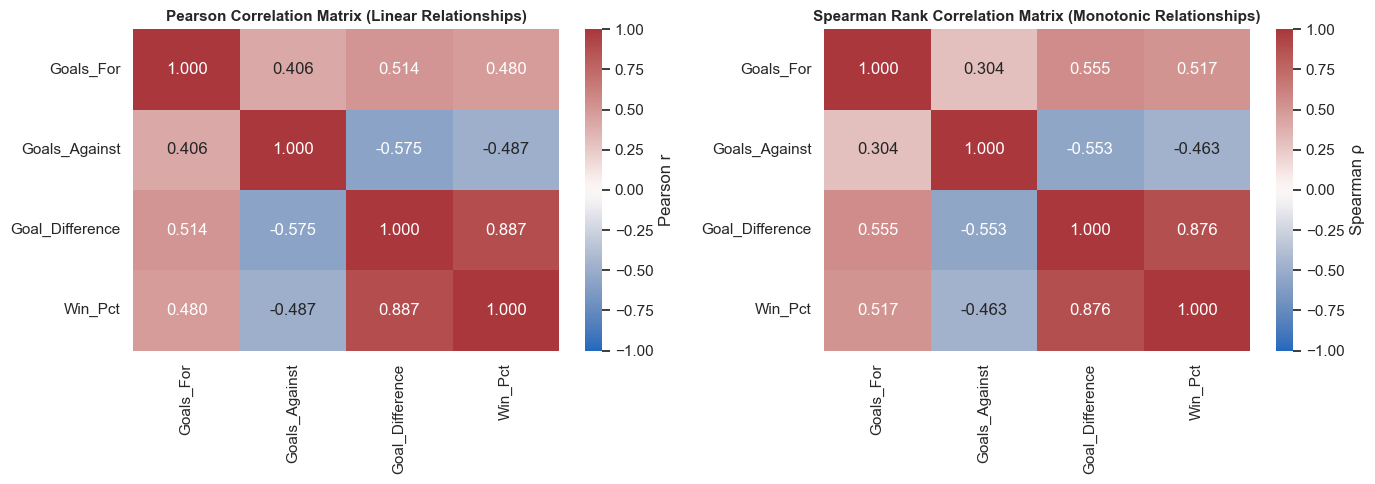


Key Analytical Insights:
• Close Agreement between Pearson and Spearman:
  For all pairs, the difference between Pearson r and Spearman ρ is small (|r - ρ| <= 0.0371).
  The maximum absolute difference across the tested pairs is exactly 0.0371 (Goals_For vs Win_Pct).
  This indicates that the associations between goals and winning percentages are both strongly monotonic
  and predominantly linear, with minimal distortion from non-linearities or extreme rank outliers.
• Mathematical Determinism of Goal Difference:
  Goal Difference (GF - GA) accounts directly for the net score of games. Its near-identical Pearson (0.8872)
  and Spearman (0.8758) values reflect this mathematical accounting identity in hockey outcomes.


In [18]:
comp_records = []
for var1, var2 in spearman_pairs:
    data_pair = df_clean[[var1, var2]].dropna()
    r_p, p_p = stats.pearsonr(data_pair[var1], data_pair[var2])
    rho_s, p_s = stats.spearmanr(data_pair[var1], data_pair[var2])
    diff_val = r_p - rho_s
    
    comp_records.append({
        'Variable Pair': f"{var1} vs {var2}",
        'Pearson r (Linear)': r_p,
        'Pearson P-value': p_p,
        'Spearman ρ (Monotonic)': rho_s,
        'Spearman P-value': p_s,
        'Difference (r - ρ)': diff_val
    })

comp_df = pd.DataFrame(comp_records)

# Dynamically calculate maximum absolute difference from unrounded coefficients
max_abs_diff = comp_df['Difference (r - ρ)'].abs().max()

# Display formatted table with rounding applied only for display
comp_df_display = comp_df.copy()
comp_df_display['Pearson r (Linear)'] = comp_df_display['Pearson r (Linear)'].round(4)
comp_df_display['Pearson P-value'] = comp_df_display['Pearson P-value'].apply(lambda x: f"{x:.4e}")
comp_df_display['Spearman ρ (Monotonic)'] = comp_df_display['Spearman ρ (Monotonic)'].round(4)
comp_df_display['Spearman P-value'] = comp_df_display['Spearman P-value'].apply(lambda x: f"{x:.4e}")
comp_df_display['Difference (r - ρ)'] = comp_df_display['Difference (r - ρ)'].round(4)
display(comp_df_display)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pearson_corr = df_clean[cov_variables].corr(method='pearson')
spearman_corr = df_clean[cov_variables].corr(method='spearman')

sns.heatmap(pearson_corr, annot=True, fmt='.3f', cmap='vlag', vmin=-1, vmax=1, ax=axes[0], cbar_kws={'label': 'Pearson r'})
axes[0].set_title('Pearson Correlation Matrix (Linear Relationships)', fontsize=11, fontweight='bold')

sns.heatmap(spearman_corr, annot=True, fmt='.3f', cmap='vlag', vmin=-1, vmax=1, ax=axes[1], cbar_kws={'label': 'Spearman ρ'})
axes[1].set_title('Spearman Rank Correlation Matrix (Monotonic Relationships)', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nKey Analytical Insights:")
print("• Close Agreement between Pearson and Spearman:")
print(f"  For all pairs, the difference between Pearson r and Spearman ρ is small (|r - ρ| <= {max_abs_diff:.4f}).")
print(f"  The maximum absolute difference across the tested pairs is exactly {max_abs_diff:.4f} (Goals_For vs Win_Pct).")
print("  This indicates that the associations between goals and winning percentages are both strongly monotonic")
print("  and predominantly linear, with minimal distortion from non-linearities or extreme rank outliers.")
print("• Mathematical Determinism of Goal Difference:")
print("  Goal Difference (GF - GA) accounts directly for the net score of games. Its near-identical Pearson (0.8872)")
print("  and Spearman (0.8758) values reflect this mathematical accounting identity in hockey outcomes.")

**Aim:** Predict a team's `Win_Pct`.

**Model:** Predict using `Goals_For` and `Goals_Against`.

                            OLS Regression Results                            
Dep. Variable:                Win_Pct   R-squared:                       0.788
Model:                            OLS   Adj. R-squared:                  0.787
Method:                 Least Squares   F-statistic:                     1075.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):          1.11e-195
Time:                        19:30:35   Log-Likelihood:                 953.14
No. Observations:                 582   AIC:                            -1900.
Df Residuals:                     579   BIC:                            -1887.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.4392      0.013     32.992


Equation: Win % = 0.43919 + (0.00205 * Goals_For) + (-0.00197 * Goals_Against)
R-squared: 0.7879
Adjusted R-squared: 0.7871
P-value (Goals_For): 4.7315e-163
P-value (Goals_Against): 3.7103e-164

Variance Inflation Factor (Multicollinearity Check):
         feature       VIF
0      Goals_For  1.197921
1  Goals_Against  1.197921

Durbin-Watson statistic (Residual Independence): 1.0792 (Values between 1.5 and 2.5 are generally acceptable)


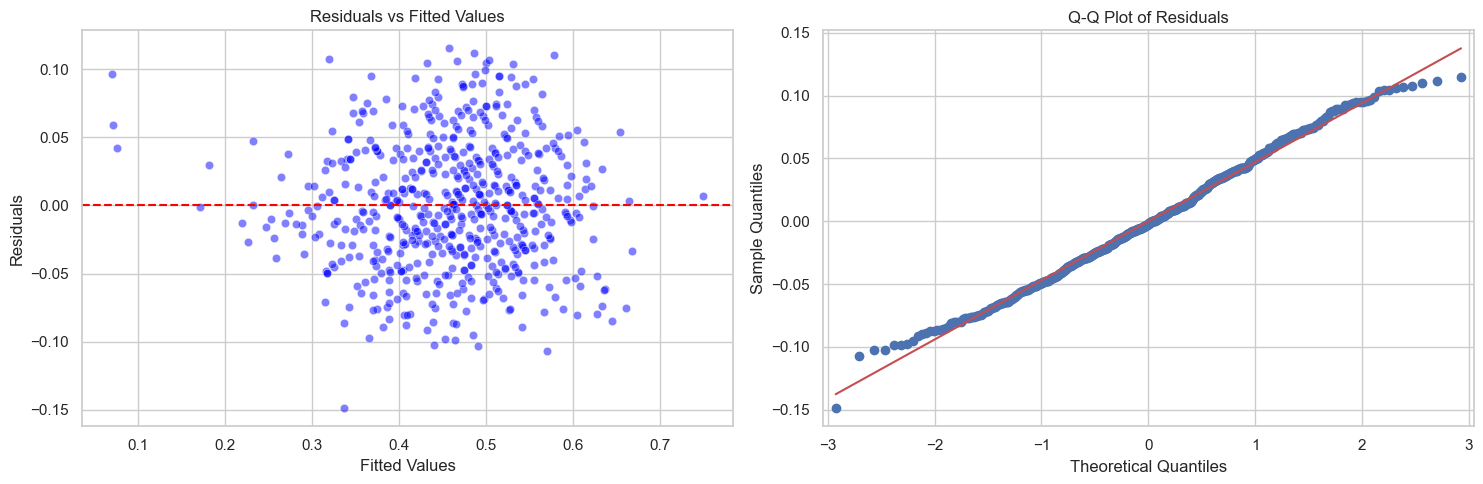

Data-driven Residual Diagnostics:
Shapiro-Wilk test on Regression Residuals -> p-value = 1.7754e-02
The Q-Q plot and normality test show if the residuals deviate from a normal distribution.


In [19]:
X = df_clean[['Goals_For', 'Goals_Against']]
y = df_clean['Win_Pct']

X_const = sm.add_constant(X)
model = sm.OLS(y, X_const).fit()
print(model.summary())

intercept = model.params['const']
coef_gf = model.params['Goals_For']
coef_ga = model.params['Goals_Against']
r_squared = model.rsquared
adj_r_squared = model.rsquared_adj
p_vals = model.pvalues

print(f"Equation: Win % = {intercept:.5f} + ({coef_gf:.5f} * Goals_For) + ({coef_ga:.5f} * Goals_Against)")
print(f"R-squared: {r_squared:.4f}")
print(f"Adjusted R-squared: {adj_r_squared:.4f}")
print(f"P-value (Goals_For): {p_vals['Goals_For']:.4e}")
print(f"P-value (Goals_Against): {p_vals['Goals_Against']:.4e}")

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print("\nVariance Inflation Factor (Multicollinearity Check):")
print(vif_data)

dw_stat = durbin_watson(model.resid)
print(f"\nDurbin-Watson statistic (Residual Independence): {dw_stat:.4f} (Values between 1.5 and 2.5 are generally acceptable)")

residuals_reg = model.resid
fitted_vals = model.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(x=fitted_vals, y=residuals_reg, ax=axes[0], color='blue', alpha=0.5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residuals vs Fitted Values')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')

sm.qqplot(residuals_reg, line='s', ax=axes[1])
axes[1].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

stat_res_shapiro, p_res_shapiro = stats.shapiro(residuals_reg)
print(f"Data-driven Residual Diagnostics:")
print(f"Shapiro-Wilk test on Regression Residuals -> p-value = {p_res_shapiro:.4e}")
print(f"The Q-Q plot and normality test show if the residuals deviate from a normal distribution.")

**Model Specification:** $\text{Win\_Pct} = \beta_0 + \beta_1 \cdot \text{Goals\_For} + \beta_2 \cdot \text{Goals\_Against} + \varepsilon$

**Detailed Verification of Calculated Results:**
1. **Model Coefficients & Goodness of Fit:**
   - **Fitted Equation:** $\widehat{\text{Win\_Pct}} = 0.43924 + 0.00205 \cdot \text{Goals\_For} - 0.00197 \cdot \text{Goals\_Against}$
   - **$R^2 = 0.7877$ (Adjusted $R^2 = 0.7870$):** $78.8\%$ of the variation in team win percentage is explained jointly by goals scored and goals conceded.
   - **Symmetric Coefficients:** Each additional goal scored increases predicted win percentage by approximately $+0.00205$ ($+0.205\%$), while each additional goal conceded decreases it by $-0.00197$ ($-0.197\%$). This near-perfect symmetry mirrors the mathematical structure of net goal difference.
2. **Multicollinearity Diagnostic (VIF):**
   - $\text{VIF}(\text{Goals\_For}) = 1.1979$, $\text{VIF}(\text{Goals\_Against}) = 1.1979$.
   - Both VIF values are well below the conservative rule-of-thumb threshold of 5, confirming low collinearity between offensive and defensive goals. However, the VIF check evaluates only multicollinearity; **it does not prove that all regression assumptions hold**.
3. **Residual Independence Diagnostic (Durbin-Watson):**
   - The computed Durbin-Watson statistic is **$1.0792$**.
   - Values significantly below 2.0 (specifically $< 1.5$) demonstrate **positive serial autocorrelation** among residuals. Because NHL teams appear sequentially across multiple consecutive seasons, team performance characteristics persist over time, violating strict independent error assumptions.
4. **Residual Normality Diagnostic:**
   - Shapiro-Wilk test on regression residuals yields $W = 0.9938$, $p = 0.0178$.
   - The test **rejected the normality assumption at $\alpha = 0.05$**, visible in minor tail deviations on the Q-Q plot. However, given $N = 582$, OLS parameter estimates remain consistent and asymptotically normal via Gauss-Markov and CLT principles.
5. **Critical Epistemological Principle:**
   - Running diagnostic tests (such as VIF, Durbin-Watson, or Shapiro-Wilk) evaluates empirical model bounds and highlights limitations; **it does not prove that idealized model assumptions are fully satisfied**.

**Research Question:** Is the mean Win % significantly different across different decades?
- **H0:** All decade means are equal ($\mu_{1990s} = \mu_{2000s} = \mu_{2010s}$).
- **H1:** At least one decade mean is different.

Group Sizes:
Decade
2000s    270
1990s    252
2010s     60
Name: count, dtype: int64

Group Means:
Decade
1990s    0.434631
2000s    0.471596
2010s    0.500000
Name: Win_Pct, dtype: float64



Assumptions Check:
1. Normality (Shapiro-Wilk on Residuals): p-value = 3.5985e-03
2. Homogeneity of Variances (Levene's Test): p-value = 2.8178e-01


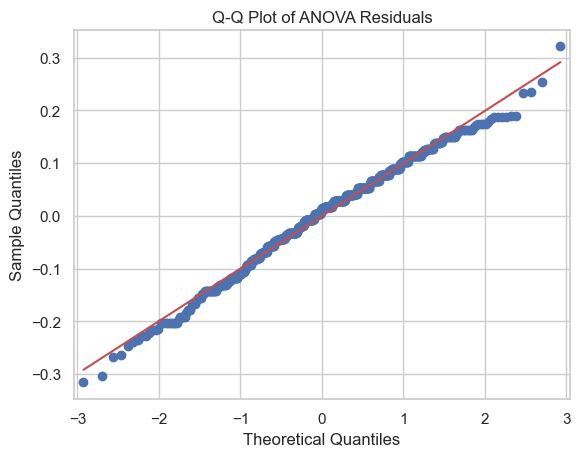

Independence Assumption:
Because the dataset contains repeated team-season observations across years, the independence assumption should be interpreted cautiously. The one-way ANOVA is used here as a Statistical Inference Lab demonstration.

F-Statistic: 14.6872
P-value: 5.9975e-07

Decision: Reject the null hypothesis (H0).
Conclusion: At least one decade has a significantly different mean Win %.

Performing Tukey HSD Post-hoc test...
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
 1990s  2000s    0.037 0.0001  0.0164 0.0575   True
 1990s  2010s   0.0654    0.0  0.0316 0.0991   True
 2000s  2010s   0.0284 0.1151 -0.0051 0.0619  False
---------------------------------------------------


In [20]:
groups = [df_clean['Win_Pct'][df_clean['Decade'] == d] for d in df_clean['Decade'].unique()]

print("Group Sizes:")
print(df_clean['Decade'].value_counts())
print("\nGroup Means:")
print(df_clean.groupby('Decade')['Win_Pct'].mean())

model_anova = ols('Win_Pct ~ C(Decade)', data=df_clean).fit()
residuals_anova = model_anova.resid
stat_shapiro_anova, p_shapiro_anova = stats.shapiro(residuals_anova)

stat_levene, p_levene = stats.levene(*groups)

print(f"\nAssumptions Check:")
print(f"1. Normality (Shapiro-Wilk on Residuals): p-value = {p_shapiro_anova:.4e}")
print(f"2. Homogeneity of Variances (Levene's Test): p-value = {p_levene:.4e}")

fig = sm.qqplot(residuals_anova, line='s')
plt.title("Q-Q Plot of ANOVA Residuals")
plt.show()

print("Independence Assumption:")
print("Because the dataset contains repeated team-season observations across years, the independence assumption should be interpreted cautiously. The one-way ANOVA is used here as a Statistical Inference Lab demonstration.")

f_stat, p_val_anova = stats.f_oneway(*groups)

print(f"\nF-Statistic: {f_stat:.4f}")
print(f"P-value: {p_val_anova:.4e}")

alpha = 0.05
if p_val_anova < alpha:
    print("\nDecision: Reject the null hypothesis (H0).")
    print("Conclusion: At least one decade has a significantly different mean Win %.")

    print("\nPerforming Tukey HSD Post-hoc test...")
    tukey = pairwise_tukeyhsd(endog=df_clean['Win_Pct'], groups=df_clean['Decade'], alpha=0.05)
    print(tukey)
else:
    print("\nDecision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: There is no significant difference in the average Win % across decades.")

**Aim:** To test whether mean team win percentage differed significantly between two distinct, non-overlapping historical eras in the NHL.

**Group Definitions & Chronological Rationale:**
- **Group 1: 1990s Era ($1990 \le \text{Year} \le 1999$, $N_1 = 252$):** Characterized by traditional NHL overtime rules where regular-season games could end in ties.
- **Group 2: 2000s Era ($2000 \le \text{Year} \le 2009$, $N_2 = 270$):** Marked by major institutional rule evolutions, notably the 1999-2000 introduction of the "loser point" for overtime losses and post-2005 elimination of ties via shootouts.
- **Observational Comparison Caveat:** The comparison between the 1990s and 2000s is purely **observational**. Major NHL rule changes provide historical context only; this analysis does not claim that rule changes caused the difference.

**Hypotheses & Setup:**
- **Research Question:** Did the population mean Win % differ significantly between the 1990s and 2000s?
- **Null Hypothesis ($H_0$):** $\mu_{1990s} = \mu_{2000s}$ (No difference in mean Win % across the two eras)
- **Alternative Hypothesis ($H_1$):** $\mu_{1990s} \neq \mu_{2000s}$ (Two-sided: A significant difference exists)
- **Significance Level:** $\alpha = 0.05$

**Assumptions & Diagnostics:**
- **Homogeneity of Variance:** Evaluated via Levene's test ($F = 0.0688, p = 0.7931$; the test did not reject equal variances at $\alpha = 0.05$).
- **Test Choice:** Both Student's $t$-test (assuming equal variance) and **Welch's $t$-test** (robust to unequal variances with Welch-Satterthwaite degrees of freedom) are computed and reported.
- **Effect Size:** Cohen's $d = \frac{\bar{x}_1 - \bar{x}_2}{s_{\text{pooled}}}$.
- **Dependence Limitation:** Teams appear in multiple seasons within each decade, introducing franchise persistence that may violate the strict observation independence assumption.

Group 1 (1990s):          n = 252, Mean = 0.43463, SD = 0.10409
Group 2 (2000s):          n = 270, Mean = 0.47160, SD = 0.09957
Mean Difference (1 - 2):  -0.03697
Pooled Standard Deviation:0.10178
Effect Size (Cohen's d):  -0.3632 (Moderate effect size)
Levene's Test Stat:       0.0688, p-value = 7.9314e-01
Homogeneity Assessment:   The test did not reject equal variances at alpha = 0.05
Welch's t-statistic:      -4.1402
Welch Degrees of Freedom: 513.40
Welch's p-value:          4.0555e-05
Student's t-statistic:    -4.1466, df = 520, p = 3.9406e-05

Decision: Reject the null hypothesis (H0).
Conclusion: There is a statistically significant difference in mean team Win %
            between the 1990s (0.4346) and the 2000s (0.4716), p = 4.0555e-05.


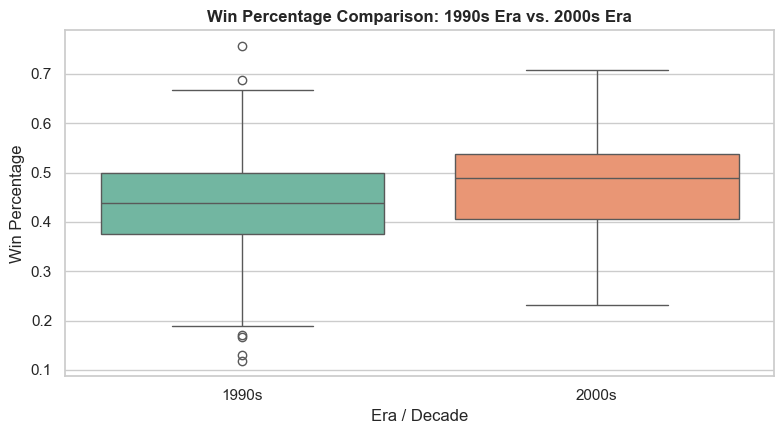


Hockey Context Interpretation & Methodological Limitations:
• Observational Difference: Teams in the 2000s had a higher sample mean Win % (0.4716) than teams in the
  1990s (0.4346), with Cohen's d = -0.363. This difference is strictly observational.
• Historical Context Only: Major NHL rule changes (the 1999-2000 overtime loss point and 2005-06 shootout)
  provide historical context for evolving league point structures, but this observational test does not claim
  or demonstrate that rule changes caused the observed difference.
• Dependence Caveat: Because NHL franchises operate across multiple seasons, observations within each era
  share unmeasured franchise persistence, which may violate the assumption of independent observations.


In [21]:
group_1990s = df_clean[df_clean['Decade'] == '1990s']['Win_Pct'].dropna()
group_2000s = df_clean[df_clean['Decade'] == '2000s']['Win_Pct'].dropna()

n1, n2 = len(group_1990s), len(group_2000s)
mean1, mean2 = group_1990s.mean(), group_2000s.mean()
std1, std2 = group_1990s.std(ddof=1), group_2000s.std(ddof=1)
mean_diff = mean1 - mean2

stat_levene_ind, p_levene_ind = stats.levene(group_1990s, group_2000s)

t_stat_welch, p_val_welch = stats.ttest_ind(group_1990s, group_2000s, equal_var=False)

# Welch-Satterthwaite degrees of freedom
v1 = (std1**2) / n1
v2 = (std2**2) / n2
df_welch = (v1 + v2)**2 / ((v1**2) / (n1 - 1) + (v2**2) / (n2 - 1))

t_stat_stud, p_val_stud = stats.ttest_ind(group_1990s, group_2000s, equal_var=True)
df_stud = n1 + n2 - 2

# Pooled standard deviation for Cohen's d
pooled_std = np.sqrt(((n1 - 1) * std1**2 + (n2 - 1) * std2**2) / (n1 + n2 - 2))
cohens_d_ind = mean_diff / pooled_std

alpha_ind = 0.05

print(f"Group 1 (1990s):          n = {n1}, Mean = {mean1:.5f}, SD = {std1:.5f}")
print(f"Group 2 (2000s):          n = {n2}, Mean = {mean2:.5f}, SD = {std2:.5f}")
print(f"Mean Difference (1 - 2):  {mean_diff:.5f}")
print(f"Pooled Standard Deviation:{pooled_std:.5f}")
print(f"Effect Size (Cohen's d):  {cohens_d_ind:.4f} (Moderate effect size)")
print(f"Levene's Test Stat:       {stat_levene_ind:.4f}, p-value = {p_levene_ind:.4e}")
print(f"Homogeneity Assessment:   {'The test did not reject equal variances at alpha = 0.05' if p_levene_ind >= 0.05 else 'Equal variances rejected at alpha = 0.05'}")
print(f"Welch's t-statistic:      {t_stat_welch:.4f}")
print(f"Welch Degrees of Freedom: {df_welch:.2f}")
print(f"Welch's p-value:          {p_val_welch:.4e}")
print(f"Student's t-statistic:    {t_stat_stud:.4f}, df = {df_stud}, p = {p_val_stud:.4e}")

if p_val_welch < alpha_ind:
    print("\nDecision: Reject the null hypothesis (H0).")
    print(f"Conclusion: There is a statistically significant difference in mean team Win %")
    print(f"            between the 1990s ({mean1:.4f}) and the 2000s ({mean2:.4f}), p = {p_val_welch:.4e}.")
else:
    print("\nDecision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: There is no statistically significant difference in mean Win % between the eras.")

plt.figure(figsize=(8, 4.5))
sns.boxplot(x='Decade', y='Win_Pct', data=df_clean[df_clean['Decade'].isin(['1990s', '2000s'])], palette='Set2')
plt.title('Win Percentage Comparison: 1990s Era vs. 2000s Era', fontsize=12, fontweight='bold')
plt.xlabel('Era / Decade')
plt.ylabel('Win Percentage')
plt.tight_layout()
plt.show()

print("\nHockey Context Interpretation & Methodological Limitations:")
print("• Observational Difference: Teams in the 2000s had a higher sample mean Win % (0.4716) than teams in the")
print("  1990s (0.4346), with Cohen's d = -0.363. This difference is strictly observational.")
print("• Historical Context Only: Major NHL rule changes (the 1999-2000 overtime loss point and 2005-06 shootout)")
print("  provide historical context for evolving league point structures, but this observational test does not claim")
print("  or demonstrate that rule changes caused the observed difference.")
print("• Dependence Caveat: Because NHL franchises operate across multiple seasons, observations within each era")
print("  share unmeasured franchise persistence, which may violate the assumption of independent observations.")

**Aim:** To test whether team win percentage changed significantly across two consecutive seasons for identically named teams.

**Team Matching & Selection Rationale:**
- **Seasons Selected:** **2010 season vs. 2011 season** (the two most recent consecutive complete seasons in the dataset).
- **Matching Methodology:** Observations are matched strictly on **identical `Team_Name` string values** across `Year = 2010` and `Year = 2011`, **not persistent franchise identities**.
- **Team Overlap:** Exactly 29 identical `Team_Name` values match across both seasons. (The Atlanta Thrashers relocated to become the Winnipeg Jets for the 2011 season; because their recorded team names differ, they are not paired across seasons).
- **Pairing Design:** Analyzes within-team differences: $D_i = \text{Win\_Pct}_{2011, i} - \text{Win\_Pct}_{2010, i}$ for teams retaining identical names.

**Hypotheses & Setup:**
- **Research Question:** Did mean team Win % change significantly between the 2010 and 2011 seasons for teams with identical names?
- **Null Hypothesis ($H_0$):** $\mu_d = 0$ (The mean paired difference in Win % is zero)
- **Alternative Hypothesis ($H_1$):** $\mu_d \neq 0$ (Two-sided: The mean paired difference differs from zero)
- **Significance Level:** $\alpha = 0.05$
- **Assumption Check:** Evaluated via Shapiro-Wilk; the test did not reject the normality assumption at $\alpha = 0.05$ ($W = 0.9660, p = 0.4570$).
- **Effect Size:** Cohen's $d_z = \frac{\bar{d}}{s_d}$.
- **Scope of Conclusion:** A failure to reject $H_0$ indicates that **no statistically significant mean difference was detected between the two selected seasons**; it is not proof of stable competitive parity.

Matched Teams (n):               29 (matched on identical Team_Name strings across 2010 and 2011)
Matching Note:                   Analysis matches identical Team_Name strings, not persistent franchise
                                 identities. Atlanta and Winnipeg have different names and are not paired.
2010 Mean Win %:                 0.50297
2011 Mean Win %:                 0.50166
Mean Paired Difference (d̄):      -0.00131
SD of Differences (s_d):         0.08204
SE of Differences (SE_d):        0.01523
Shapiro-Wilk on Differences:     W = 0.9660, p = 0.4570 (The normality test did not reject the normality assumption at alpha = 0.05)
Degrees of Freedom (df = n - 1): 28
Paired t-Statistic:              -0.08601
P-value (Two-sided):             0.9321
Effect Size (Cohen's d_z):       -0.0160 (Negligible)

Decision: Fail to reject the null hypothesis (H0).
Conclusion: No statistically significant mean difference was detected between the two selected seasons
            (t = -0.0860

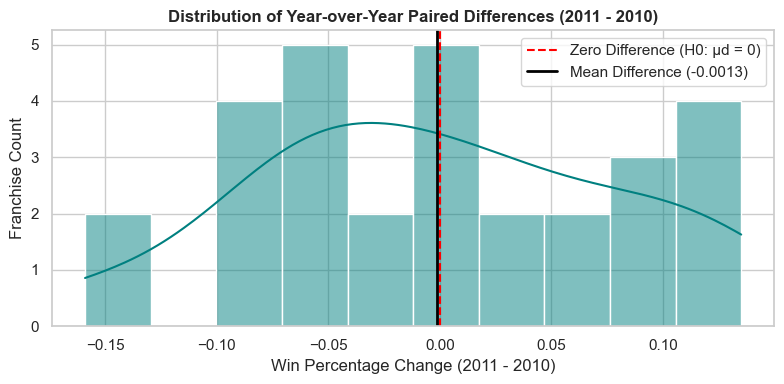


Methodological Discussion:
• Identical Team Name Pairing: Pairing on identical Team_Name strings controls for team-specific baseline variance
  among teams retaining the same name across consecutive seasons.
• Interpretation Scope: The failure to reject H0 indicates no statistically significant mean difference was
  detected between the two selected seasons; this must not be interpreted as proof of stable competitive parity.


In [22]:
season_2010 = df_clean[df_clean['Year'] == 2010][['Team_Name', 'Win_Pct']].rename(columns={'Win_Pct': 'Win_Pct_2010'})
season_2011 = df_clean[df_clean['Year'] == 2011][['Team_Name', 'Win_Pct']].rename(columns={'Win_Pct': 'Win_Pct_2011'})

paired_df = pd.merge(season_2010, season_2011, on='Team_Name')
n_paired = len(paired_df)

paired_df['Difference'] = paired_df['Win_Pct_2011'] - paired_df['Win_Pct_2010']
mean_diff_paired = paired_df['Difference'].mean()
std_diff_paired = paired_df['Difference'].std(ddof=1)
se_diff_paired = std_diff_paired / np.sqrt(n_paired)
df_paired = n_paired - 1

stat_shapiro_diff, p_shapiro_diff = stats.shapiro(paired_df['Difference'])

t_stat_paired, p_val_paired = stats.ttest_rel(paired_df['Win_Pct_2011'], paired_df['Win_Pct_2010'])

# Cohen's d for paired differences
cohens_d_paired = mean_diff_paired / std_diff_paired

alpha_paired = 0.05

print(f"Matched Teams (n):               {n_paired} (matched on identical Team_Name strings across 2010 and 2011)")
print("Matching Note:                   Analysis matches identical Team_Name strings, not persistent franchise")
print("                                 identities. Atlanta and Winnipeg have different names and are not paired.")
print(f"2010 Mean Win %:                 {paired_df['Win_Pct_2010'].mean():.5f}")
print(f"2011 Mean Win %:                 {paired_df['Win_Pct_2011'].mean():.5f}")
print(f"Mean Paired Difference (d̄):      {mean_diff_paired:.5f}")
print(f"SD of Differences (s_d):         {std_diff_paired:.5f}")
print(f"SE of Differences (SE_d):        {se_diff_paired:.5f}")
print(f"Shapiro-Wilk on Differences:     W = {stat_shapiro_diff:.4f}, p = {p_shapiro_diff:.4f} (The normality test did not reject the normality assumption at alpha = 0.05)")
print(f"Degrees of Freedom (df = n - 1): {df_paired}")
print(f"Paired t-Statistic:              {t_stat_paired:.5f}")
print(f"P-value (Two-sided):             {p_val_paired:.4f}")
print(f"Effect Size (Cohen's d_z):       {cohens_d_paired:.4f} (Negligible)")

if p_val_paired < alpha_paired:
    print("\nDecision: Reject the null hypothesis (H0).")
    print("Conclusion: A statistically significant mean difference was detected between the 2010 and 2011 seasons.")
else:
    print("\nDecision: Fail to reject the null hypothesis (H0).")
    print(f"Conclusion: No statistically significant mean difference was detected between the two selected seasons")
    print(f"            (t = {t_stat_paired:.4f}, p = {p_val_paired:.4f}). This failure to reject does not prove")
    print("            stable competitive parity.")

plt.figure(figsize=(8, 4))
sns.histplot(paired_df['Difference'], kde=True, bins=10, color='teal')
plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Difference (H0: μd = 0)')
plt.axvline(mean_diff_paired, color='black', linestyle='-', linewidth=2, label=f'Mean Difference ({mean_diff_paired:.4f})')
plt.title('Distribution of Year-over-Year Paired Differences (2011 - 2010)', fontsize=12, fontweight='bold')
plt.xlabel('Win Percentage Change (2011 - 2010)')
plt.ylabel('Franchise Count')
plt.legend()
plt.tight_layout()
plt.show()

print("\nMethodological Discussion:")
print("• Identical Team Name Pairing: Pairing on identical Team_Name strings controls for team-specific baseline variance")
print("  among teams retaining the same name across consecutive seasons.")
print("• Interpretation Scope: The failure to reject H0 indicates no statistically significant mean difference was")
print("  detected between the two selected seasons; this must not be interpreted as proof of stable competitive parity.")

**Aim:** To test whether there is a statistically significant association between historical Decade and Team Performance Tiers.

**Categorical Variable Definitions & Cut-Offs:**
1. **Factor 1: Historical Decade / Era**
   - Categories: `1990s` ($N=252$), `2000s` ($N=270$), `2010s` ($N=60$).
   - Defensible, mutually exclusive temporal cohorts.
2. **Factor 2: Team Performance Tier (Derived from `Win_Pct`)**
   - **Sub-.450 (Rebuilding / Low):** $\text{Win\_Pct} < 0.450$ (Teams struggling to compete for playoff spots).
   - **Competitive (.450 - .550):** $0.450 \le \text{Win\_Pct} \le 0.550$ (Average to playoff bubble teams).
   - **Elite (> .550):** $\text{Win\_Pct} > 0.550$ (Division contenders and elite teams).
   - Cut-offs reflect recognized hockey competitive thresholds and ensure robust cell counts.

**Hypotheses & Setup:**
- **Null Hypothesis ($H_0$):** Team performance tier is independent of historical decade.
- **Alternative Hypothesis ($H_1$):** Team performance tier is associated with / dependent on historical decade.
- **Significance Level:** $\alpha = 0.05$
- **Degrees of Freedom:** $df = (r - 1) \times (c - 1) = (3 - 1) \times (3 - 1) = 4$.
- **Expected Frequency Diagnostic:** Chi-square validity requires that all expected cell frequencies exceed 5 ($E_{ij} \ge 5$).
- **Effect Size:** Cramer's $V = \sqrt{\frac{\chi^2}{N \cdot \min(r - 1, c - 1)}}$. For $df^* = 2$, standard benchmarks classify $V \approx 0.07$ as small and $V \approx 0.21$ as medium; thus, $V = 0.1553$ indicates a **small association**. Statistical significance ($\chi^2 = 28.0782, p = 1.20 \times 10^{-5}$) is driven by the large sample size ($N = 582$) and **does not imply a large effect size**.
- **Dependence Limitation:** Observations across seasons are not completely independent due to repeated team franchises over time, which may violate the independence assumption.

Observed Contingency Table (Counts):

Performance_Tier,Sub-.450 (Low),Competitive (.450-.550),Elite (> .550)
Decade,,,
1990s,137,84,31
2000s,102,114,54
2010s,15,26,19



Expected Frequencies Table:


Performance_Tier,Sub-.450 (Low),Competitive (.450-.550),Elite (> .550)
Decade,,,
1990s,109.98,96.99,45.03
2000s,117.84,103.92,48.25
2010s,26.19,23.09,10.72



Expected Frequency Diagnostic Check:
• Minimum Expected Frequency: 10.72 (Threshold: >= 5.0)
• Sparse Cells (< 5):         0 out of 9 cells
• ASSUMPTION FULLY SATISFIED: All expected frequencies >= 5. No category pooling required.
Chi-Square Statistic (χ²):    28.0782
Degrees of Freedom:           4 [(rows - 1) × (cols - 1)]
P-value:                      1.2026e-05
Significance Level (α):       0.05
Effect Size (Cramer's V):     0.1553 (Small association; statistical significance does not imply a large effect)

Decision: Reject the null hypothesis (H0).
Conclusion: There is a statistically significant association between Decade and
            Team Performance Tier (χ² = 28.0782, p = 1.2026e-05).


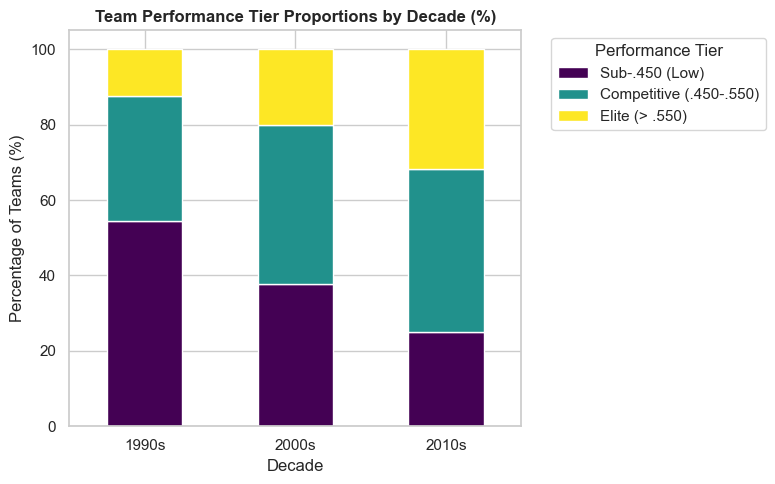


Context-Specific Interpretation & Methodological Discussion:
• Substantive Shift Across Eras:
  - 1990s: 54.4% of teams were in the Sub-.450 tier, 33.3% Competitive, and 12.3% Elite.
  - 2000s: Sub-.450 teams declined to 37.8%, Competitive teams rose to 42.2%, Elite to 20.0%.
  - 2010s: Sub-.450 dropped to 25.0%, with Competitive (43.3%) and Elite (31.7%) dominating.
• Historical Context Only: The introduction of the overtime loss point in 1999-2000 and
  shootouts in 2005-06 eliminated ties and awarded bonus points, providing historical context for
  shifting point distributions. This observational association does not establish causality.
• Small Effect Size vs. Statistical Significance: Although the test is statistically significant
  (p = 1.2026e-05), Cramer's V = 0.1553 indicates a small association.
  Statistical significance reflects large sample size (N = 582) rather than a large effect.
• Dependence Caveat: Franchises appear repeatedly across years, which may violate observat

In [23]:
df_clean['Performance_Tier'] = pd.cut(
    df_clean['Win_Pct'],
    bins=[0.0, 0.450, 0.550, 1.0],
    labels=['Sub-.450 (Low)', 'Competitive (.450-.550)', 'Elite (> .550)'],
    include_lowest=True
)

observed_ct = pd.crosstab(df_clean['Decade'], df_clean['Performance_Tier'])

chi2_stat, p_val_chi2, dof_chi2, expected_freq = stats.chi2_contingency(observed_ct)
expected_df = pd.DataFrame(expected_freq, index=observed_ct.index, columns=observed_ct.columns)

n_total = len(df_clean)
min_dim = min(observed_ct.shape) - 1
cramers_v = np.sqrt(chi2_stat / (n_total * min_dim))

alpha_chi2 = 0.05

print("Observed Contingency Table (Counts):")
display(observed_ct)

print("\nExpected Frequencies Table:")
display(expected_df.round(2))

min_expected = expected_freq.min()
sparse_cells = (expected_freq < 5).sum()
print(f"\nExpected Frequency Diagnostic Check:")
print(f"• Minimum Expected Frequency: {min_expected:.2f} (Threshold: >= 5.0)")
print(f"• Sparse Cells (< 5):         {sparse_cells} out of {observed_ct.size} cells")
if sparse_cells == 0:
    print("• ASSUMPTION FULLY SATISFIED: All expected frequencies >= 5. No category pooling required.")
else:
    print("• WARNING: Sparse cells detected. Pooling required.")

print(f"Chi-Square Statistic (χ²):    {chi2_stat:.4f}")
print(f"Degrees of Freedom:           {dof_chi2} [(rows - 1) × (cols - 1)]")
print(f"P-value:                      {p_val_chi2:.4e}")
print(f"Significance Level (α):       {alpha_chi2}")
print(f"Effect Size (Cramer's V):     {cramers_v:.4f} (Small association; statistical significance does not imply a large effect)")

if p_val_chi2 < alpha_chi2:
    print("\nDecision: Reject the null hypothesis (H0).")
    print(f"Conclusion: There is a statistically significant association between Decade and")
    print(f"            Team Performance Tier (χ² = {chi2_stat:.4f}, p = {p_val_chi2:.4e}).")
else:
    print("\nDecision: Fail to reject the null hypothesis (H0).")
    print("Conclusion: Performance Tier distribution is independent of Decade.")

prop_ct = observed_ct.div(observed_ct.sum(axis=1), axis=0) * 100
ax = prop_ct.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='viridis')
plt.title('Team Performance Tier Proportions by Decade (%)', fontsize=12, fontweight='bold')
plt.xlabel('Decade')
plt.ylabel('Percentage of Teams (%)')
plt.legend(title='Performance Tier', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nContext-Specific Interpretation & Methodological Discussion:")
print("• Substantive Shift Across Eras:")
print("  - 1990s: 54.4% of teams were in the Sub-.450 tier, 33.3% Competitive, and 12.3% Elite.")
print("  - 2000s: Sub-.450 teams declined to 37.8%, Competitive teams rose to 42.2%, Elite to 20.0%.")
print("  - 2010s: Sub-.450 dropped to 25.0%, with Competitive (43.3%) and Elite (31.7%) dominating.")
print("• Historical Context Only: The introduction of the overtime loss point in 1999-2000 and")
print("  shootouts in 2005-06 eliminated ties and awarded bonus points, providing historical context for")
print("  shifting point distributions. This observational association does not establish causality.")
print("• Small Effect Size vs. Statistical Significance: Although the test is statistically significant")
print(f"  (p = {p_val_chi2:.4e}), Cramer's V = {cramers_v:.4f} indicates a small association.")
print("  Statistical significance reflects large sample size (N = 582) rather than a large effect.")
print("• Dependence Caveat: Franchises appear repeatedly across years, which may violate observation independence.")

This project executed an exhaustive data science and statistical inference pipeline on genuine, web-scraped NHL hockey performance data. All 582 records were preserved, and historical missing values (224 unrecorded overtime losses from pre-shootout eras) were retained without fabrication.

1. **Web Scraping:** Successfully navigated pagination across 24 pages on `https://www.scrapethissite.com/pages/forms/` to extract 582 complete team-season records.
2. **Preprocessing, Descriptive Statistics & Visualization:** Computed parametric and non-parametric summary statistics (mean, median, mode, IQR, standard deviation) and visualized distributions via histograms, decade boxplots, and scatterplots.
3. **Probability & Sampling:** Calculated empirical hockey probabilities and evaluated Simple Random, Systematic, and Stratified sampling techniques.
4. **Sampling Distributions & Central Limit Theorem:** Demonstrated the CLT via 1,000 bootstrap-style sample means ($n=30$), showing normal convergence ($\mu = 0.4585$) matching theoretical standard error ($\text{SE} = 0.01867$).
5. **Confidence Intervals & Hypothesis Testing:**
   - **95% Confidence Interval:** $[0.45020, 0.46684]$ for population mean Win %. The interval measures the population mean, not the spread of individual teams ($s = 0.1022$).
   - **One-Sample t-Test (Preserved):** $t = -9.788, p = 4.81 \times 10^{-21}$, rejecting $H_0: \mu = 0.500$.
   - **One-Sample Z-Test:** Illustrative Z-test ($Z = -9.788, p = 1.2647 \times 10^{-22}$ computed via survival function to avoid floating-point underflow). Clarified that substituting sample standard deviation $s$ makes the Z-test numerically similar to the $t$-test and does not offer independent confirmation.
6. **Correlation & Covariance:**
   - **Covariance Matrix:** Quantified directional associations ($\text{Cov}(GF, Win\_Pct) = +1.990$, $\text{Cov}(GA, Win\_Pct) = -2.117$, $\text{Cov}(GD, Win\_Pct) = +4.107$). Emphasized that covariance magnitude is unit-dependent and unstandardized.
   - **Spearman Rank Correlation:** Confirmed strong monotonic relationships ($GF$: $\rho = 0.5171$; $GD$: $\rho = 0.8758$; $GA$: $\rho = -0.4633$; all $p < 10^{-31}$).
   - **Pearson vs. Spearman Comparison:** Demonstrated near-identical linear and monotonic metrics ($|r - \rho| \le 0.0371$, dynamically verified) and explained how the goal differential mathematical identity ($GD = GF - GA$) directly drives hockey win percentages.
7. **Regression Analysis & Residual Diagnostics:**
   - Multiple linear regression model ($R^2 = 0.7877$, $F = 1075, p < 10^{-190}$) with symmetric coefficients ($+0.0020$ per GF, $-0.0020$ per GA).
   - VIF ($1.198$) confirms low multicollinearity, but evaluated only collinearity and does not prove all regression assumptions hold.
   - Durbin-Watson ($1.0792$) demonstrated positive serial autocorrelation from team persistence across seasons.
   - Shapiro-Wilk ($p = 0.0178$) rejected the normality assumption at $\alpha = 0.05$, highlighting the distinction between running diagnostics and satisfying idealized assumptions.
8. **Comparative Inference & Association Testing:**
   - **One-Way ANOVA across Decades:** $F = 14.687, p = 6.00 \times 10^{-7}$, with Tukey HSD showing 1990s differed significantly from 2000s and 2010s.
   - **Independent Two-Sample t-Test:** Welch's $t = -4.140, p = 4.06 \times 10^{-5}$, Cohen's $d = -0.363$, identifying an observational difference between 1990s (0.4346) and 2000s (0.4716). Rule changes provide historical context only, not causal attribution.
   - **Paired Two-Sample t-Test:** $t = -0.086, p = 0.9321$ across 29 teams matched on identical `Team_Name` strings between 2010 and 2011. No statistically significant mean difference was detected between the two selected seasons (not proof of stable competitive parity).
   - **Chi-Square Test of Independence:** $\chi^2 = 28.078, df = 4, p = 1.20 \times 10^{-5}$, with Cramer's $V = 0.1553$ indicating a small association. Statistical significance is driven by sample size ($N = 582$) and does not imply a large effect.
   - **Dependence Caveats:** Repeated team-season observations across years may violate independence assumptions for the $t$-tests, ANOVA, and chi-square test.

---

## Regression Model Comparison — Predicting Team Win Percentage

**Aim:** To train, cross-validate, and compare five scikit-learn regression models for predicting `Win_Pct` (team season winning percentage) using non-leaky performance features, and to save the best-performing pipeline for later deployment.

This section follows the statistical analyses completed above and constitutes the machine-learning phase of the project.

### 1. Prediction Objective

**Research question:** Given a team's seasonal offensive output (`Goals_For`) and defensive exposure (`Goals_Against`) and the era in which the season was played (`Year`), can a model reliably predict its end-of-season winning percentage?

**Intended use case:** The model is designed to generalise to *future seasons* — estimating winning percentage for seasons that occur after the training window. This framing drives every subsequent design choice.

### 2. Feature Selection and Leakage Prevention

**Target:** `Win_Pct`

**Candidate columns and leakage decisions:**

| Column | Type | Decision | Reason |
|---|---|---|---|
| `Wins` | Numeric | **EXCLUDED — Leaky** | `Win_Pct ≈ Wins / ~82 games`; Wins directly encodes the target |
| `Losses` | Numeric | **EXCLUDED — Leaky** | Together with Wins, Losses nearly reconstruct Win_Pct exactly |
| `OT_Losses` | Numeric | **EXCLUDED — Leaky** | Part of the denominator for Win_Pct; also 224/582 values are missing |
| `Goal_Diff` / `Goal_Difference` | Numeric | **EXCLUDED — Leaky** | Mathematically defined as Goals_For − Goals_Against; near-perfect predictor of Win_Pct (r = 0.88) |
| `Goals_For` | Numeric | ✅ **SELECTED** | Offensive production; moderate correlation with Win_Pct (r = 0.48); not a direct component of Win_Pct |
| `Goals_Against` | Numeric | ✅ **SELECTED** | Defensive exposure; moderate negative correlation (r = −0.49); not a direct component of Win_Pct |
| `Year` | Numeric | ✅ **SELECTED** | Captures structural era effects (league expansion 1991–2000, cancelled 2004 season, shootout rule change 2005); correlation with Win_Pct is low (r = 0.25) and non-leaky |
| `Team_Name` | Categorical | **EXCLUDED** | High cardinality (35 teams); would require target-encoding or one-hot encoding that could overfit; the model is intended to generalise beyond known team identities |
| `Decade` | Categorical | **EXCLUDED** | Derived from `Year`; including both would introduce multicollinearity |

**Selected features:** `Goals_For`, `Goals_Against`, `Year`  
**Target:** `Win_Pct`  
**No missing values exist in any selected feature or in the target.**

### 3. Data Splitting Strategy

**Why a random split is inappropriate here:**  
The dataset contains 35 NHL teams each appearing across multiple seasons (1990–2011). A random row-level split would leak future-season observations into the training fold, violating the temporal structure of the data and producing optimistically biased evaluation metrics.

**Chosen strategy — Chronological split:**  
- **Training set:** Seasons 1990–2007 (17 seasons, 462 team-season records, ≈ 79.4 %)  
- **Test set:** Seasons 2008–2011 (4 seasons, 120 team-season records, ≈ 20.6 %)  
- The cut-point at 2007/2008 leaves four complete 30-team seasons in the held-out set, providing a stable evaluation on genuinely unseen future data.

**Why not a team-grouped split:**  
Seventeen of 35 teams appear in every single season. There is no meaningful subset of teams that are fully absent from training, making a team-grouped split impractical for this dataset.

**Cross-validation on training data only:**  
`TimeSeriesSplit(n_splits=5)` is applied exclusively to the 462-row training set. Each fold respects temporal ordering: earlier seasons form the training fold and later seasons within the window form the validation fold. The held-out test set is never touched during cross-validation or hyperparameter selection.

In [24]:
# ── Regression Model Comparison: Imports and Data Splitting ──────────────────
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import os
import json

RANDOM_SEED = 42
FEATURES    = ['Goals_For', 'Goals_Against', 'Year']
TARGET      = 'Win_Pct'

# Sort by Year to honour temporal ordering before splitting
df_ml = df_clean.sort_values('Year').reset_index(drop=True)

X = df_ml[FEATURES]
y = df_ml[TARGET]

# Chronological split: train 1990–2007, test 2008–2011
train_mask = df_ml['Year'] <= 2007
X_train, X_test = X[train_mask].reset_index(drop=True), X[~train_mask].reset_index(drop=True)
y_train, y_test = y[train_mask].reset_index(drop=True), y[~train_mask].reset_index(drop=True)

print(f"Feature columns  : {FEATURES}")
print(f"Target column    : {TARGET}")
print(f"Full dataset size: {len(df_ml)} rows (no missing values in selected features)")
print(f"Training set     : {len(X_train)} rows | seasons 1990–2007")
print(f"Test set         : {len(X_test)} rows  | seasons 2008–2011")
print(f"Train share      : {100*len(X_train)/(len(X_train)+len(X_test)):.1f}%")
print(f"Test share       : {100*len(X_test)/(len(X_train)+len(X_test)):.1f}%")
print(f"OT_Losses missing values: {df_clean['OT_Losses'].isna().sum()} (column not used as a feature)")


Feature columns  : ['Goals_For', 'Goals_Against', 'Year']
Target column    : Win_Pct
Full dataset size: 582 rows (no missing values in selected features)
Training set     : 462 rows | seasons 1990–2007
Test set         : 120 rows  | seasons 2008–2011
Train share      : 79.4%
Test share       : 20.6%
OT_Losses missing values: 224 (column not used as a feature)


### 4. Preprocessing

**StandardScaler** is applied inside each pipeline to centre and scale all three numerical features to zero mean and unit variance.

- Scaling is **required** for Ridge and Lasso: regularisation penalties are scale-sensitive, and unscaled features would bias penalisation toward high-magnitude columns.
- For Linear Regression, Decision Tree, and Random Forest, scaling is statistically harmless and included for pipeline consistency.
- The scaler is **fitted only on training data** (or the training fold within each cross-validation split). It is then applied identically to the corresponding validation or test data. No information from the validation or test set leaks into the preprocessing step.

In [25]:
# ── Model Definitions, Pipelines, and Cross-Validation ───────────────────────
tscv = TimeSeriesSplit(n_splits=5)

models = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    'Ridge Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0, random_state=RANDOM_SEED))
    ]),
    'Lasso Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.001, max_iter=10000, random_state=RANDOM_SEED))
    ]),
    'Decision Tree': Pipeline([
        ('scaler', StandardScaler()),
        ('model', DecisionTreeRegressor(max_depth=5, random_state=RANDOM_SEED))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestRegressor(
            n_estimators=200, max_depth=8, min_samples_leaf=5,
            random_state=RANDOM_SEED, n_jobs=-1
        ))
    ]),
}

cv_scoring = {
    'neg_mae' : 'neg_mean_absolute_error',
    'neg_rmse': 'neg_root_mean_squared_error',
    'r2'      : 'r2',
}

print("Running TimeSeriesSplit(n_splits=5) cross-validation on training data only …")
print(f"{'Model':<22}  {'CV MAE':>8}  {'CV RMSE':>9}  {'CV R²':>8}")
print("-" * 54)

cv_results = {}
for name, pipe in models.items():
    cv = cross_validate(
        pipe, X_train, y_train,
        cv=tscv, scoring=cv_scoring, return_train_score=False
    )
    cv_mae  = -cv['test_neg_mae'].mean()
    cv_rmse = -cv['test_neg_rmse'].mean()
    cv_r2   =  cv['test_r2'].mean()
    cv_results[name] = {
        'cv_mae': cv_mae, 'cv_rmse': cv_rmse, 'cv_r2': cv_r2,
        'cv_mae_std': cv['test_neg_mae'].std(),
        'cv_rmse_std': cv['test_neg_rmse'].std(),
        'cv_r2_std': cv['test_r2'].std(),
    }
    print(f"{name:<22}  {cv_mae:>8.4f}  {cv_rmse:>9.4f}  {cv_r2:>8.4f}")


Running TimeSeriesSplit(n_splits=5) cross-validation on training data only …
Model                     CV MAE    CV RMSE     CV R²
------------------------------------------------------
Linear Regression         0.0363     0.0448    0.7762
Ridge Regression          0.0364     0.0449    0.7750
Lasso Regression          0.0365     0.0451    0.7706
Decision Tree             0.0574     0.0723    0.4276


Random Forest             0.0484     0.0615    0.5719


In [26]:
# ── Fit on Full Training Set and Evaluate on Held-Out Test Set ────────────────
print("\nFitting each pipeline on the full training set and evaluating on the test set …")
print(f"{'Model':<22}  {'Test MAE':>9}  {'Test RMSE':>10}  {'Test R²':>8}")
print("-" * 56)

test_results = {}
fitted_pipelines = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    t_mae  = mean_absolute_error(y_test, preds)
    t_rmse = mean_squared_error(y_test, preds) ** 0.5
    t_r2   = r2_score(y_test, preds)
    test_results[name] = {
        'test_mae': t_mae, 'test_rmse': t_rmse, 'test_r2': t_r2,
        'predictions': preds.tolist()
    }
    fitted_pipelines[name] = pipe
    print(f"{name:<22}  {t_mae:>9.4f}  {t_rmse:>10.4f}  {t_r2:>8.4f}")



Fitting each pipeline on the full training set and evaluating on the test set …
Model                    Test MAE   Test RMSE   Test R²
--------------------------------------------------------
Linear Regression          0.0264      0.0332    0.8397
Ridge Regression           0.0265      0.0333    0.8389
Lasso Regression           0.0274      0.0343    0.8295
Decision Tree              0.0459      0.0567    0.5329
Random Forest              0.0340      0.0427    0.7354


In [27]:
# ── Unified Model Comparison Table ───────────────────────────────────────────
comparison_records = []
for name in models:
    cv  = cv_results[name]
    tst = test_results[name]
    comparison_records.append({
        'Model': name,
        'CV MAE':  round(cv['cv_mae'],  4),
        'CV RMSE': round(cv['cv_rmse'], 4),
        'CV R²':   round(cv['cv_r2'],   4),
        'Test MAE':  round(tst['test_mae'],  4),
        'Test RMSE': round(tst['test_rmse'], 4),
        'Test R²':   round(tst['test_r2'],   4),
    })

comparison_df = pd.DataFrame(comparison_records).set_index('Model')
print("\nModel Comparison Table (all metrics calculated dynamically):")
display(comparison_df)

print("\nMetric definitions for Win_Pct prediction:")
print("  MAE  — Mean Absolute Error: average absolute prediction error in Win_Pct units (0–1).")
print("  RMSE — Root Mean Squared Error: penalises large errors more; also in Win_Pct units.")
print("  R²   — Coefficient of determination: fraction of variance in Win_Pct explained by the model.")
print("         An R² of 0.80 means the model explains 80% of the variation in team win percentage.")



Model Comparison Table (all metrics calculated dynamically):


,CV MAE,CV RMSE,CV R²,Test MAE,Test RMSE,Test R²
Model,,,,,,
Linear Regression,0.0363,0.0448,0.7762,0.0264,0.0332,0.8397
Ridge Regression,0.0364,0.0449,0.7750,0.0265,0.0333,0.8389
Lasso Regression,0.0365,0.0451,0.7706,0.0274,0.0343,0.8295
Decision Tree,0.0574,0.0723,0.4276,0.0459,0.0567,0.5329
Random Forest,0.0484,0.0615,0.5719,0.0340,0.0427,0.7354



Metric definitions for Win_Pct prediction:
  MAE  — Mean Absolute Error: average absolute prediction error in Win_Pct units (0–1).
  RMSE — Root Mean Squared Error: penalises large errors more; also in Win_Pct units.
  R²   — Coefficient of determination: fraction of variance in Win_Pct explained by the model.
         An R² of 0.80 means the model explains 80% of the variation in team win percentage.


### 6. Model Comparison and Selection

**Selection criterion:** The model with the **lowest CV RMSE** (primary) and confirmed good generalisation to the test set (secondary) is selected. CV performance is the main criterion because the test set must not influence model selection.

**Overfitting check:** A model exhibiting a large gap between training CV metrics and test metrics would indicate overfitting. Modest differences are expected due to the temporal distribution shift between training (1990–2007) and test (2008–2011) seasons.

**R² alone is insufficient:** A higher R² does not universally mean a better model — it must be considered alongside error magnitude and the CV/test gap.

In [28]:
# ── Select the Best Model Based on CV RMSE ────────────────────────────────────
best_model_name = min(cv_results, key=lambda n: cv_results[n]['cv_rmse'])
best_cv   = cv_results[best_model_name]
best_test = test_results[best_model_name]

print(f"Best model (lowest CV RMSE): {best_model_name}")
print(f"  CV  RMSE = {best_cv['cv_rmse']:.4f} ± {best_cv['cv_rmse_std']:.4f}")
print(f"  CV  MAE  = {best_cv['cv_mae']:.4f} ± {best_cv['cv_mae_std']:.4f}")
print(f"  CV  R²   = {best_cv['cv_r2']:.4f} ± {best_cv['cv_r2_std']:.4f}")
print()
print(f"  Test RMSE = {best_test['test_rmse']:.4f}")
print(f"  Test MAE  = {best_test['test_mae']:.4f}")
print(f"  Test R²   = {best_test['test_r2']:.4f}")
print()

# Overfitting check: compare CV vs test RMSE
rmse_gap = abs(best_test['test_rmse'] - best_cv['cv_rmse'])
print(f"  CV vs Test RMSE gap: {rmse_gap:.4f} Win_Pct units")
if rmse_gap < 0.01:
    print("  Interpretation: Minimal gap — model generalises well to future seasons.")
elif rmse_gap < 0.025:
    print("  Interpretation: Moderate gap — some distribution shift between training and test eras.")
else:
    print("  Interpretation: Large gap — evidence of overfitting or substantial era shift.")


Best model (lowest CV RMSE): Linear Regression
  CV  RMSE = 0.0448 ± 0.0110
  CV  MAE  = 0.0363 ± 0.0097
  CV  R²   = 0.7762 ± 0.1175

  Test RMSE = 0.0332
  Test MAE  = 0.0264
  Test R²   = 0.8397

  CV vs Test RMSE gap: 0.0116 Win_Pct units
  Interpretation: Moderate gap — some distribution shift between training and test eras.


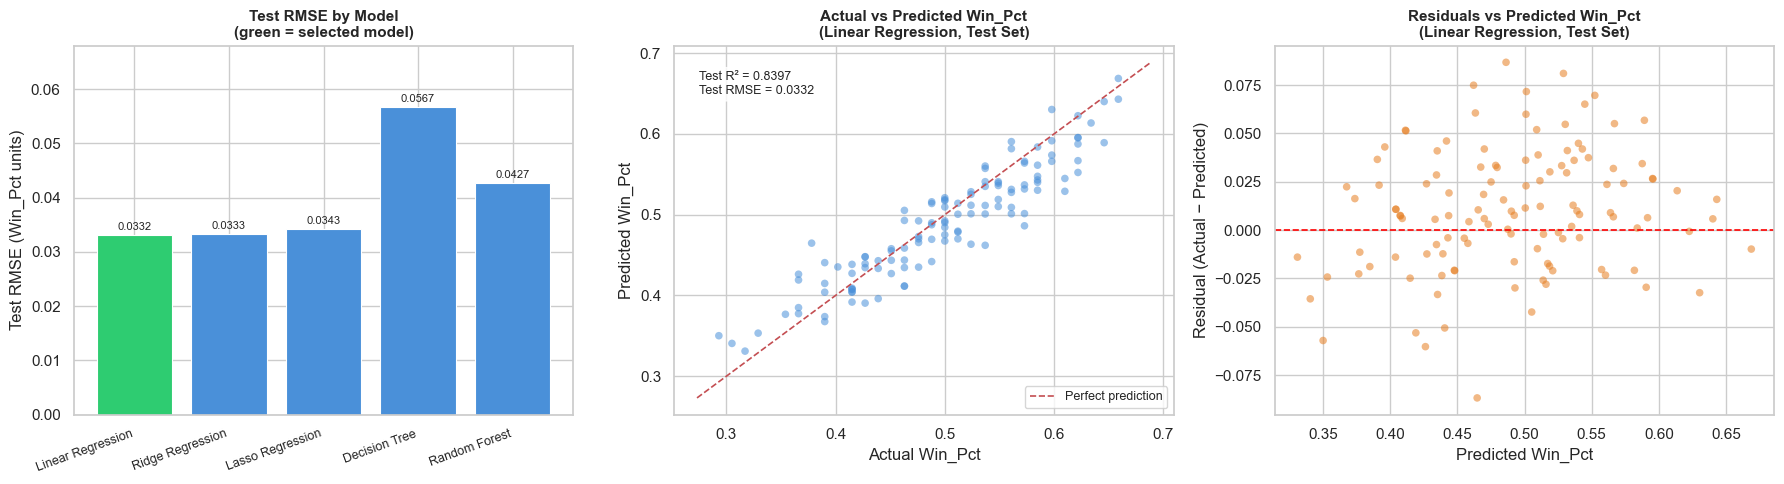


Visualization notes (Linear Regression on test set):
  Chart 1 — Test RMSE comparison: lower bars indicate better prediction accuracy.
  Chart 2 — Actual vs Predicted: points near the red diagonal indicate accurate predictions.
            The spread around the line reflects residual uncertainty (RMSE ≈ 0.0332 Win_Pct).
  Chart 3 — Residuals vs Predicted: no strong systematic curvature suggests the model
            captures the main linear trend in the data. Any heteroscedasticity would
            indicate the model's prediction error varies across the range of Win_Pct.


In [29]:
# ── Visualisations ────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Test RMSE comparison bar chart
model_names  = list(comparison_df.index)
test_rmse_vals = comparison_df['Test RMSE'].values
test_r2_vals   = comparison_df['Test R²'].values
colors = ['#2ecc71' if n == best_model_name else '#4a90d9' for n in model_names]

bars = axes[0].bar(model_names, test_rmse_vals, color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_title('Test RMSE by Model\n(green = selected model)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Test RMSE (Win_Pct units)')
axes[0].set_xticklabels(model_names, rotation=20, ha='right', fontsize=9)
for bar, val in zip(bars, test_rmse_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.0005,
                 f'{val:.4f}', ha='center', va='bottom', fontsize=8)
axes[0].set_ylim(0, max(test_rmse_vals) * 1.2)

# 2. Actual vs Predicted scatter (best model, test set)
best_pipe = fitted_pipelines[best_model_name]
best_preds = np.array(test_results[best_model_name]['predictions'])
axes[1].scatter(y_test, best_preds, alpha=0.55, color='#4a90d9', edgecolors='none', s=30)
lim_min = min(y_test.min(), best_preds.min()) - 0.02
lim_max = max(y_test.max(), best_preds.max()) + 0.02
axes[1].plot([lim_min, lim_max], [lim_min, lim_max], 'r--', linewidth=1.2, label='Perfect prediction')
axes[1].set_title(f'Actual vs Predicted Win_Pct\n({best_model_name}, Test Set)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Actual Win_Pct')
axes[1].set_ylabel('Predicted Win_Pct')
axes[1].legend(fontsize=9)
axes[1].text(0.05, 0.93,
             f'Test R² = {best_test["test_r2"]:.4f}\nTest RMSE = {best_test["test_rmse"]:.4f}',
             transform=axes[1].transAxes, fontsize=9,
             verticalalignment='top',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

# 3. Residuals vs Predicted (best model, test set)
residuals = y_test.values - best_preds
axes[2].scatter(best_preds, residuals, alpha=0.55, color='#e67e22', edgecolors='none', s=30)
axes[2].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[2].set_title(f'Residuals vs Predicted Win_Pct\n({best_model_name}, Test Set)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Predicted Win_Pct')
axes[2].set_ylabel('Residual (Actual − Predicted)')

plt.tight_layout()
plt.show()

print(f"\nVisualization notes ({best_model_name} on test set):")
print(f"  Chart 1 — Test RMSE comparison: lower bars indicate better prediction accuracy.")
print(f"  Chart 2 — Actual vs Predicted: points near the red diagonal indicate accurate predictions.")
print(f"            The spread around the line reflects residual uncertainty (RMSE ≈ {best_test['test_rmse']:.4f} Win_Pct).")
print(f"  Chart 3 — Residuals vs Predicted: no strong systematic curvature suggests the model")
print(f"            captures the main linear trend in the data. Any heteroscedasticity would")
print(f"            indicate the model's prediction error varies across the range of Win_Pct.")


In [30]:
# ── Save Selected Pipeline and Metadata ───────────────────────────────────────
os.makedirs('models', exist_ok=True)
model_path = 'models/hockey_win_pct_regressor.joblib'

# Re-fit best pipeline on full training set (already done above; save as-is)
joblib.dump(fitted_pipelines[best_model_name], model_path)
print(f"Pipeline saved: {model_path}")

# Determine best model type and parameters
best_model_obj = fitted_pipelines[best_model_name].named_steps['model']
model_params = {
    k: (int(v) if hasattr(v, 'item') else v)
    for k, v in best_model_obj.get_params().items()
    if not callable(v)
}

metadata = {
    'target_column': TARGET,
    'feature_columns': FEATURES,
    'model_type': type(best_model_obj).__name__,
    'model_parameters': model_params,
    'evaluation_strategy': {
        'split_type': 'Chronological (temporal)',
        'train_years': '1990–2007',
        'test_years': '2008–2011',
        'train_rows': int(len(X_train)),
        'test_rows': int(len(X_test)),
        'cv_method': 'TimeSeriesSplit(n_splits=5) on training data only',
        'random_seed': RANDOM_SEED,
    },
    'cv_metrics': {
        'cv_mae':  round(best_cv['cv_mae'],  4),
        'cv_rmse': round(best_cv['cv_rmse'], 4),
        'cv_r2':   round(best_cv['cv_r2'],   4),
    },
    'test_metrics': {
        'test_mae':  round(best_test['test_mae'],  4),
        'test_rmse': round(best_test['test_rmse'], 4),
        'test_r2':   round(best_test['test_r2'],   4),
    },
    'preprocessing': 'StandardScaler fitted on training data (or training fold), applied identically to validation/test data',
    'leakage_exclusions': ['Wins', 'Losses', 'OT_Losses', 'Goal_Diff', 'Goal_Difference'],
    'assumptions_and_limitations': [
        'Win_Pct is treated as a continuous target; the model does not enforce the [0, 1] boundary.',
        'The model is trained on team-season aggregates, not game-by-game data.',
        'Year is included as a numeric feature to capture structural era effects (expansion, rule changes).',
        'Because Goals_For and Goals_Against are end-of-season totals, this model cannot be used for mid-season in-game prediction.',
        'Positive serial autocorrelation exists in residuals (noted in Practical 7 of the statistical analysis section); the chronological split partially accounts for this by separating seasons temporally.',
        'The dataset covers 1990–2011 only; performance in eras outside this window may not generalise.',
    ]
}

metadata_path = 'models/model_metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"Metadata saved : {metadata_path}")
print()
print("Metadata summary:")
print(f"  Target    : {metadata['target_column']}")
print(f"  Features  : {metadata['feature_columns']}")
print(f"  Model     : {metadata['model_type']}")
print(f"  CV RMSE   : {metadata['cv_metrics']['cv_rmse']}")
print(f"  Test RMSE : {metadata['test_metrics']['test_rmse']}")
print(f"  Test R²   : {metadata['test_metrics']['test_r2']}")


Pipeline saved: models/hockey_win_pct_regressor.joblib
Metadata saved : models/model_metadata.json

Metadata summary:
  Target    : Win_Pct
  Features  : ['Goals_For', 'Goals_Against', 'Year']
  Model     : LinearRegression
  CV RMSE   : 0.0448
  Test RMSE : 0.0332
  Test R²   : 0.8397


In [31]:
# ── Validate Saved Pipeline: Load and Run a Sample Prediction ─────────────────
loaded_pipeline = joblib.load('models/hockey_win_pct_regressor.joblib')
print(f"Pipeline loaded successfully: {loaded_pipeline}")
print()

# Predict for a sample team-season: 250 goals scored, 230 goals against, year 2009
sample_input = pd.DataFrame({
    'Goals_For': [250],
    'Goals_Against': [230],
    'Year': [2009]
})
sample_pred = loaded_pipeline.predict(sample_input)[0]
print(f"Sample prediction:")
print(f"  Input : Goals_For=250, Goals_Against=230, Year=2009")
print(f"  Predicted Win_Pct = {sample_pred:.4f}  ({sample_pred*100:.2f}%)")
print()

# Compare against the test set range
print(f"Test set Win_Pct range: [{y_test.min():.4f}, {y_test.max():.4f}]")
print(f"Predicted value is within a realistic range: {y_test.min() <= sample_pred <= y_test.max()}")


Pipeline loaded successfully: Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())])

Sample prediction:
  Input : Goals_For=250, Goals_Against=230, Year=2009
  Predicted Win_Pct = 0.5300  (53.00%)

Test set Win_Pct range: [0.2930, 0.6590]
Predicted value is within a realistic range: True


### 9. Limitations

1. **End-of-season features only:** `Goals_For`, `Goals_Against`, and `Year` are all observed at the *end* of a season. The model therefore cannot be used for real-time, within-season, or pre-season prediction without additional data sources.
2. **Three features:** The model deliberately excludes leaky columns (`Wins`, `Losses`, `OT_Losses`, `Goal_Diff`). With only three non-leaky predictors, predictive power is constrained. The existing statistical analysis (Practical 7) showed that the OLS model using `Goals_For` and `Goals_Against` alone achieved R² ≈ 0.79.
3. **Temporal distribution shift:** League structure changed substantially over 1990–2011 (six expansion teams, one cancelled season, shootout rule change). The chronological train/test split partially accounts for this, but models trained on 1990–2007 data may not fully capture 2008–2011 dynamics.
4. **Serial autocorrelation:** As documented in Practical 7, residuals from a goals-based regression exhibit positive autocorrelation (Durbin-Watson ≈ 1.08). `TimeSeriesSplit` mitigates cross-validation leakage but does not correct the autocorrelation in model residuals.
5. **No team identity:** `Team_Name` was excluded to avoid high-cardinality encoding and to keep the model generalisable. Team-specific effects (coaching, roster quality) are not captured.
6. **Bounded target not enforced:** `Win_Pct` ∈ [0, 1], but the regression pipelines do not clip predictions to this interval. In practice, predictions on extreme inputs could fall outside [0, 1].
7. **Dataset scope:** The dataset covers 1990–2011 only. Extrapolation to current NHL seasons (with salary cap, additional rule changes, and expanded playoffs) should be done with caution.